# HASTIKA @ ICON-2026 — Kannada-English hate speech (Task A + Task B)
Fine-tunes **every model in the `MODELS` list independently** on both tasks, reports metrics + plots on the
**validation** split (test gold labels are not public), and writes a **separate, ready-to-submit `predictions.csv`
per model per task** for the **test** inputs. No ensembling — each model gives its own submission.

**Kaggle setup:** Settings -> *Accelerator: GPU (T4 / P100)* and *Internet: On*. Keep the notebook **private**
(dataset licence: no redistribution — the repo is cloned to `/tmp`, so raw data is never written to the output folder).

Output layout (`/kaggle/working/outputs`):
```
<model_slug>/taskA_binary/predictions.csv        <- id,label  (Hate / Non-hate)
<model_slug>/taskB_finegrained/predictions.csv   <- id,label  (Gender/Political/Religion/Geo-political/Violence/Others)
<model_slug>/<task>/*_predictions.zip            <- flat zip containing only predictions.csv
figures/*.png                                    <- every plot in this notebook
results_summary.csv                              <- validation metrics of every model x task
```

## 1. Config — the only cell you normally edit

In [1]:
# ======================= EDIT ME =======================
MODELS = [
    "ai4bharat/IndicBERTv2-MLM-only",   # IndicBERT v2 (BERT-style, tokenizer.json available)
    "l3cube-pune/kannada-bert",         # L3Cube Kannada BERT
    "google/muril-base-cased",          # MuRIL
]
TASKS = ["A", "B"]                      # "A" = binary, "B" = fine-grained (hate comments only)

EPOCHS      = 6        # max epochs (best epoch picked on validation macro-F1, early-stopped)
PATIENCE    = 3
BATCH_SIZE  = 32
LR          = 3e-5
MAX_LEN     = 128
WARMUP      = 0.1
WEIGHT_DECAY = 0.01
SEED        = 42
LR_OVERRIDE = {}       # e.g. {"google/muril-base-cased": 2e-5}

USE_CLASS_WEIGHTS_B = True    # sqrt-inverse-frequency weights for Task B (macro-F1 friendly)
RETRAIN_ON_TRAIN_PLUS_VAL = False  # True -> after picking best epoch, retrain on train+val for the test predictions
NON_HATE_LABEL = "Non-hate"   # spelling written to Task A files ("Non-hate" per CodaBench page; sample files use "Non-Hate")

# Hugging Face READ-ONLY token (only used to download models). If left empty, the Kaggle Secret named HF_TOKEN is used.
# Keep this notebook PRIVATE while a token is pasted here; revoke/rotate the token afterwards.
HF_TOKEN = ""
# =======================================================

## 2. Install, clone the HASTIKA repo, imports

In [2]:
import subprocess, sys, os
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ftfy"], check=False)

REPO_URL = "https://github.com/shankarb14/Hastika-ICON2026.git"
REPO_DIR = "/tmp/Hastika-ICON2026"       # /tmp on purpose: keeps licensed data out of the notebook output
if not os.path.isdir(REPO_DIR):
    subprocess.run(["git", "clone", "--depth", "1", REPO_URL, REPO_DIR], check=True)
print(sorted(os.listdir(os.path.join(REPO_DIR, "data"))))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 615.1 kB/s eta 0:00:00


Cloning into '/tmp/Hastika-ICON2026'...


['binary_train.csv', 'hastika_binary_test.csv', 'hastika_binary_validation.csv', 'hastika_multiclass_test.csv', 'hastika_multiclass_validation.csv', 'multiclass_train.csv']


In [3]:
import re, gc, json, html, random, shutil, time, zipfile
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from torch import nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from sklearn.metrics import (f1_score, accuracy_score, classification_report, confusion_matrix, roc_curve, auc,
                             precision_recall_curve, average_precision_score, precision_recall_fscore_support)
from sklearn.feature_extraction.text import CountVectorizer

try:
    import ftfy
    def fix_mojibake(t): return ftfy.fix_text(t, unescape_html=False)
except ImportError:                       # fallback if ftfy could not be installed
    def fix_mojibake(t):
        for enc in ("cp1252", "latin-1"):
            try: return t.encode(enc).decode("utf-8")
            except Exception: pass
        return t

# ---- Hugging Face auth (read-only token; makes gated / rate-limited downloads work)
if not HF_TOKEN:
    try:
        from kaggle_secrets import UserSecretsClient
        HF_TOKEN = UserSecretsClient().get_secret("HF_TOKEN")
    except Exception:
        HF_TOKEN = ""
if HF_TOKEN:
    os.environ["HF_TOKEN"] = HF_TOKEN
    os.environ["HUGGING_FACE_HUB_TOKEN"] = HF_TOKEN
    try:
        from huggingface_hub import login
        login(token=HF_TOKEN, add_to_git_credential=False)
    except Exception as e:
        print("HF login skipped:", type(e).__name__, e)
else:
    print("No HF token set - downloading anonymously.")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
OUT_DIR = "/kaggle/working/outputs" if os.path.isdir("/kaggle/working") else "./outputs"
FIG_DIR = os.path.join(OUT_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)
print("device:", DEVICE, "| torch", torch.__version__)

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 11})
PALETTE = plt.cm.tab10.colors
pd.set_option("display.max_colwidth", 150); pd.set_option("display.width", 200)

def seed_everything(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def savefig(name):
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, name + ".png"), dpi=130, bbox_inches="tight")
    plt.show()

def heat(ax, M, xlabels, ylabels, title, fmt="{:.0f}", cmap="Blues", vmin=None, vmax=None):
    ax.imshow(M, cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_xticks(range(len(xlabels))); ax.set_xticklabels(xlabels, rotation=40, ha="right")
    ax.set_yticks(range(len(ylabels))); ax.set_yticklabels(ylabels)
    thr = (np.nanmax(M) + np.nanmin(M)) / 2
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, fmt.format(M[i, j]), ha="center", va="center", fontsize=8,
                    color="white" if M[i, j] > thr else "black")
    ax.grid(False); ax.set_title(title)

def short(m): return m.split("/")[-1]

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


device: cuda | torch 2.11.0+cu128


## 3. Data + cleaning
The raw CSVs contain **mojibake** (Kannada script / emoji stored as `à²•...`) and HTML (`&quot;`, `<br>`).
The encoding is repaired so the Kannada-script models see real Kannada, not garbage.

In [4]:
DATA = os.path.join(REPO_DIR, "data")

def clean(t):
    t = fix_mojibake(str(t))                           # repair mojibake (Kannada / emoji)
    t = re.sub(r"<br\s*/?>", " ", t, flags=re.I)
    t = html.unescape(t)                               # &quot; &amp; ...
    t = re.sub(r"https?://\S+|www\.\S+", " URL ", t)
    t = re.sub(r"@\w+", "@user", t)
    return re.sub(r"\s+", " ", t).strip()

TASK_CFG = {
    "A": dict(name="taskA_binary", train="binary_train.csv", val="hastika_binary_validation.csv",
              test="hastika_binary_test.csv", label_col="Label", labels=["Non-Hate", "Hate"]),
    "B": dict(name="taskB_finegrained", train="multiclass_train.csv", val="hastika_multiclass_validation.csv",
              test="hastika_multiclass_test.csv", label_col="Hate Category",
              labels=["Gender", "Political", "Religion", "Geo-political", "Violence", "Others"]),
}

def norm_label(s):
    return str(s).strip().lower().replace("_", "-").replace(" ", "-")

def load_task(tk):
    c = TASK_CFG[tk]
    l2i = {norm_label(l): i for i, l in enumerate(c["labels"])}
    out = {}
    for split in ("train", "val", "test"):
        df = pd.read_csv(os.path.join(DATA, c[split]), encoding="utf-8-sig")
        df["text"] = df["Comment"].map(clean)
        if split != "test":
            df["y"] = df[c["label_col"]].map(lambda v: l2i[norm_label(v)])   # KeyError => unexpected label
        out[split] = df
    return out

DATASETS = {tk: load_task(tk) for tk in TASKS}
for tk in TASKS:
    d = DATASETS[tk]
    print(f"Task {tk}:", {k: len(v) for k, v in d.items()},
          "| train dist:", d["train"]["y"].value_counts().sort_index().to_dict())
ex = DATASETS[TASKS[0]]["train"]
print("\nCleaning example (raw -> clean):")
print(ex["Comment"].iloc[1]); print(ex["text"].iloc[1])

Task A: {'train': 6446, 'val': 806, 'test': 806} | train dist: {0: 3286, 1: 3160}
Task B: {'train': 3159, 'val': 395, 'test': 396} | train dist: {0: 1362, 1: 559, 2: 382, 3: 186, 4: 221, 5: 449}

Cleaning example (raw -> clean):
amar sir , à²à³à²¹à³à²²à²¿ Bad performance, eshto world best players à²¨ Best performance.<br> &quot; Level of KING KOHLI ðª
amar sir , ಕೊಹ್ಲಿ Bad performance, eshto world best players ನ Best performance. " Level of KING KOHLI 💪


## 4. Data inspection & visualisation (EDA)

In [5]:
# ---- hygiene / leakage table
rows = []
for tk in TASKS:
    tr, va, te = (DATASETS[tk][s] for s in ("train", "val", "test"))
    rows.append(dict(task=tk,
                     rows_changed_by_cleaning=int((tr["Comment"] != tr["text"]).sum()),
                     dup_texts_in_train=int(tr["text"].duplicated().sum()),
                     conflicting_label_dups=int(tr.groupby("text")["y"].nunique().gt(1).sum()),
                     train_val_text_overlap=len(set(tr["text"]) & set(va["text"])),
                     train_test_text_overlap=len(set(tr["text"]) & set(te["text"])),
                     empty_after_cleaning=int(sum((x["text"].str.len() == 0).sum() for x in (tr, va, te)))))
display(pd.DataFrame(rows).set_index("task"))

,rows_changed_by_cleaning,dup_texts_in_train,conflicting_label_dups,train_val_text_overlap,train_test_text_overlap,empty_after_cleaning
task,,,,,,
A,2028,37,3,11,6,0
B,801,13,2,5,4,0


/tmp/ipykernel_50/2998028167.py:22: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[1].boxplot(data, labels=labels, patch_artist=True, showfliers=False)


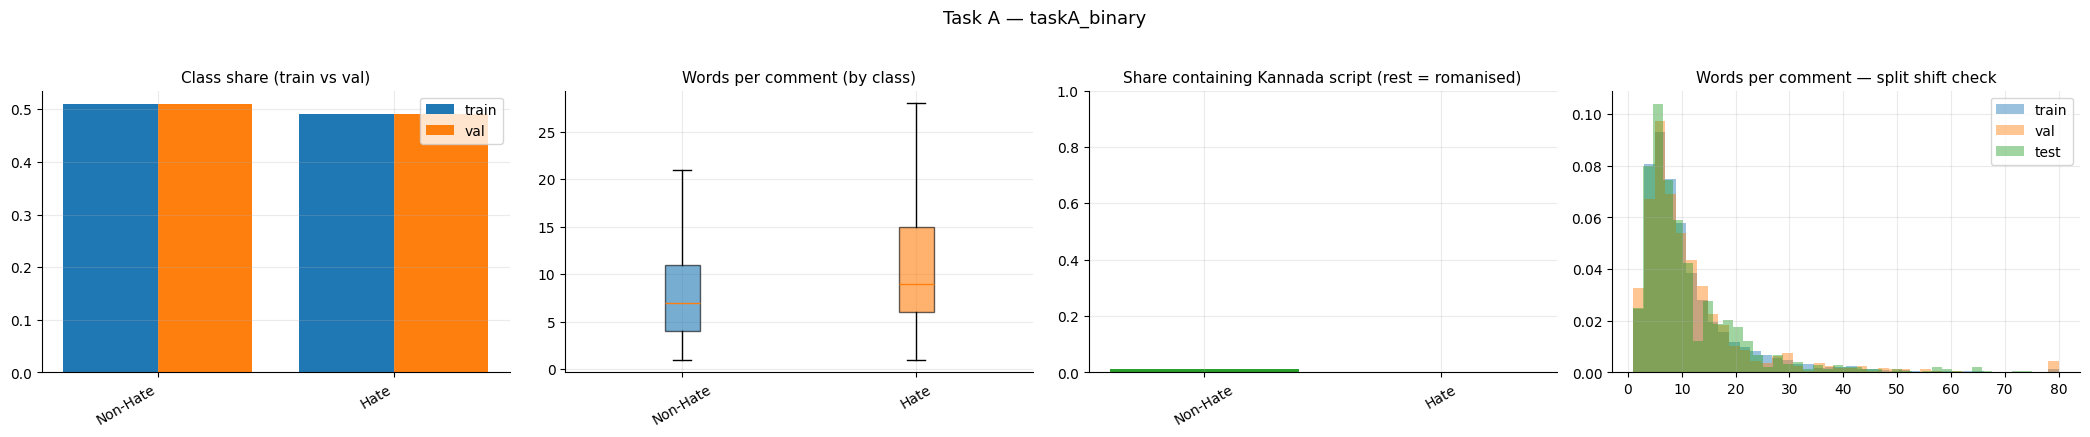

/tmp/ipykernel_50/2998028167.py:22: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[1].boxplot(data, labels=labels, patch_artist=True, showfliers=False)


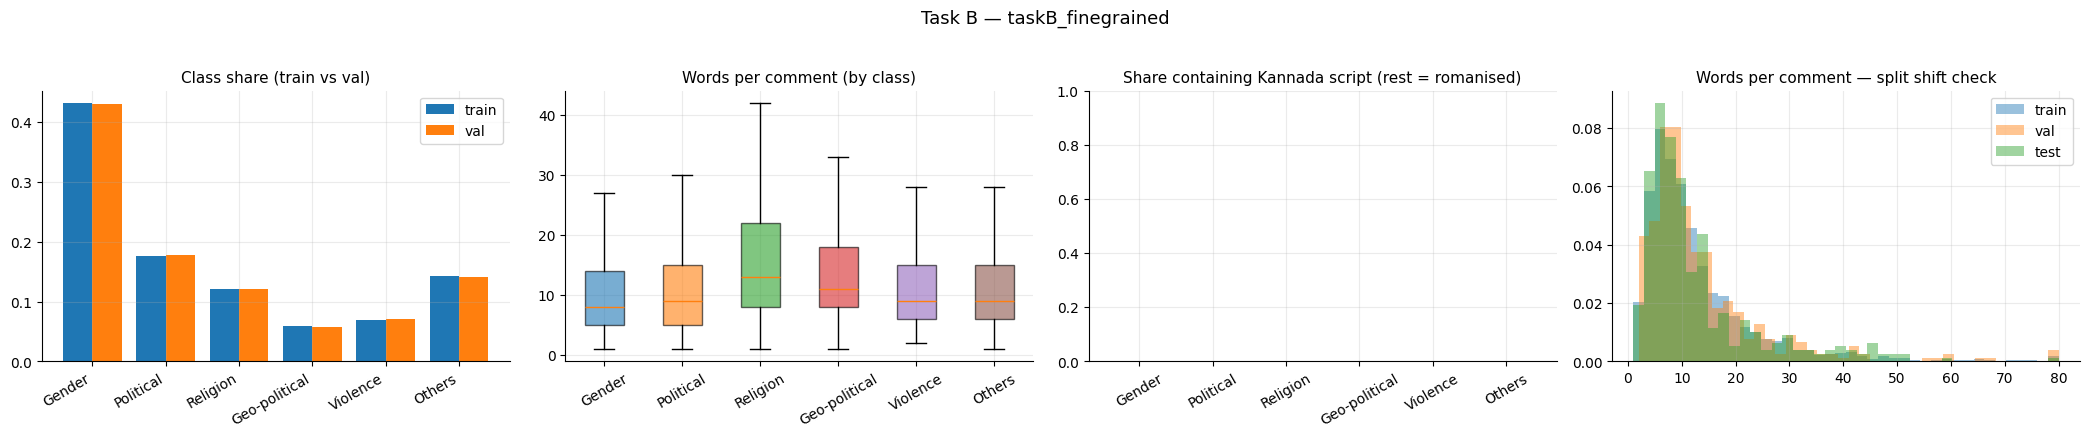

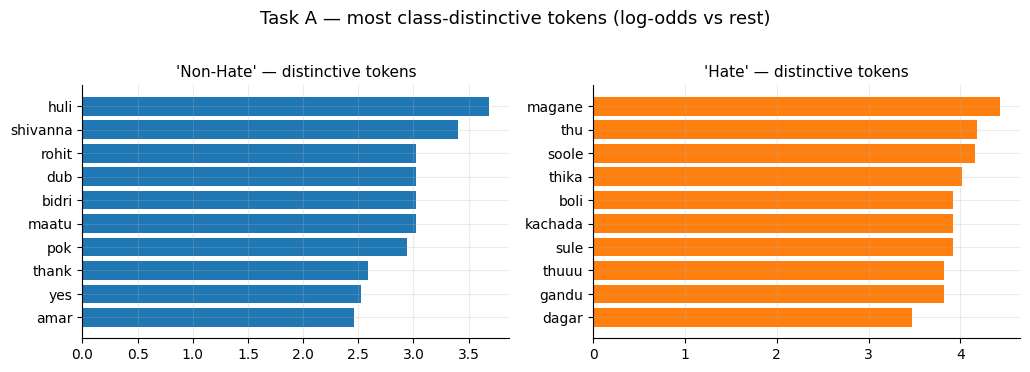

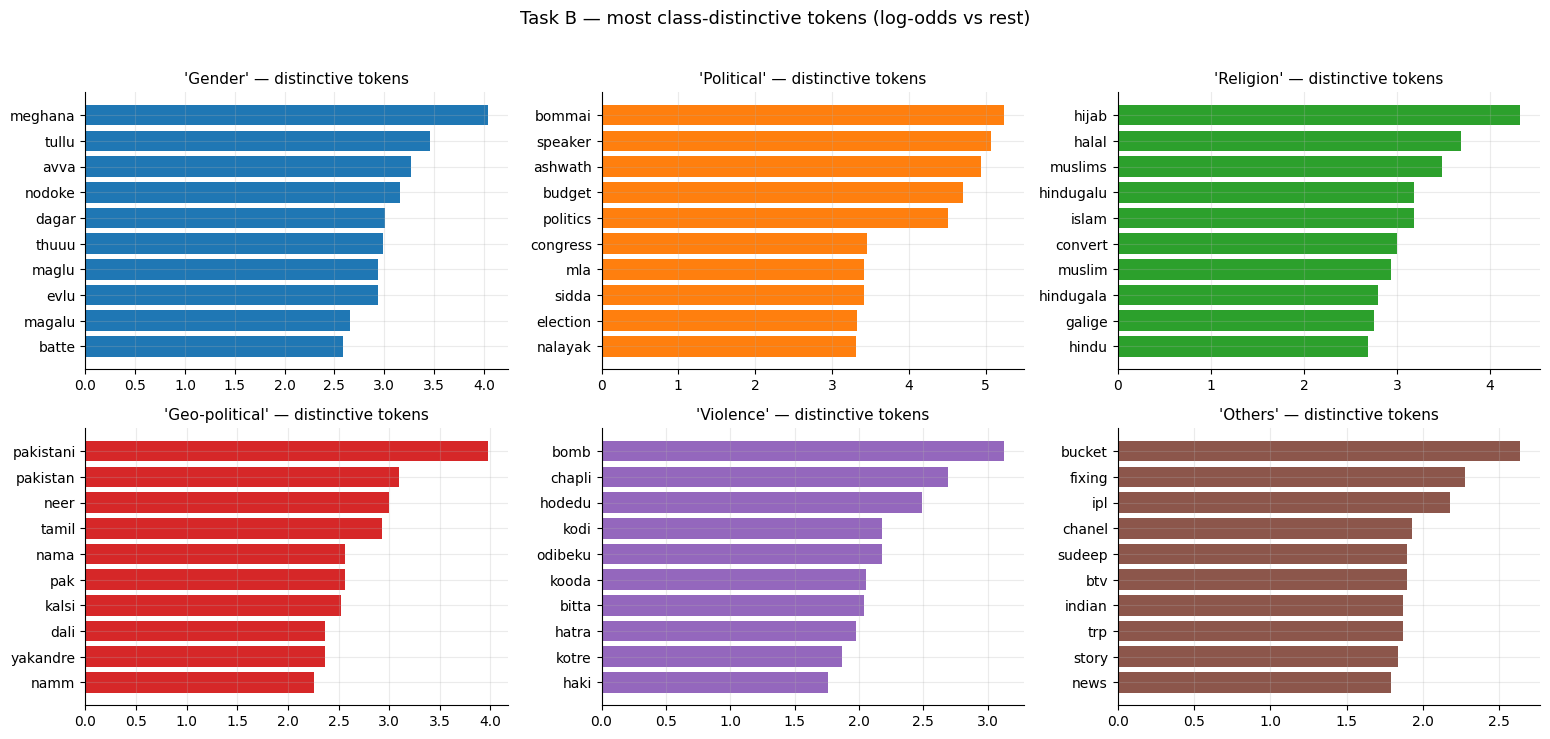

In [6]:
KN = re.compile("[" + chr(0x0C80) + "-" + chr(0x0CFF) + "]")      # Kannada script block

def eda_frame(tk, split="train"):
    d = DATASETS[tk][split].copy()
    d["label"] = d["y"].map(lambda i: TASK_CFG[tk]["labels"][i])
    d["n_words"] = d["text"].str.split().str.len()
    d["has_kn"] = d["text"].map(lambda t: bool(KN.search(t)))
    return d

for tk in TASKS:
    labels = TASK_CFG[tk]["labels"]; n = len(labels)
    tr, va = eda_frame(tk, "train"), eda_frame(tk, "val")
    fig, axes = plt.subplots(1, 4, figsize=(21, 4.2))
    # 1) class balance train vs val
    x = np.arange(n); w = 0.4
    axes[0].bar(x - w / 2, [(tr["y"] == i).mean() for i in range(n)], w, label="train", color=PALETTE[0])
    axes[0].bar(x + w / 2, [(va["y"] == i).mean() for i in range(n)], w, label="val", color=PALETTE[1])
    axes[0].set_xticks(x); axes[0].set_xticklabels(labels, rotation=30, ha="right"); axes[0].legend()
    axes[0].set_title("Class share (train vs val)")
    # 2) words per comment by class
    data = [tr.loc[tr["y"] == i, "n_words"].clip(upper=tr["n_words"].quantile(0.99)) for i in range(n)]
    bp = axes[1].boxplot(data, labels=labels, patch_artist=True, showfliers=False)
    for p, c in zip(bp["boxes"], PALETTE): p.set_facecolor(c); p.set_alpha(0.6)
    axes[1].tick_params(axis="x", rotation=30); axes[1].set_title("Words per comment (by class)")
    # 3) script mix
    axes[2].bar(labels, [tr.loc[tr["y"] == i, "has_kn"].mean() for i in range(n)], color=PALETTE[2])
    axes[2].set_ylim(0, 1); axes[2].tick_params(axis="x", rotation=30)
    axes[2].set_title("Share containing Kannada script (rest = romanised)")
    # 4) length distribution overall + split sizes
    for s, df in (("train", tr), ("val", va), ("test", eda_frame(tk, "val").assign(n_words=DATASETS[tk]["test"]["text"].str.split().str.len().values[:len(va)] if len(DATASETS[tk]["test"]) >= len(va) else va["n_words"]))):
        axes[3].hist(df["n_words"].clip(upper=80), bins=40, alpha=0.45, density=True, label=s)
    axes[3].legend(); axes[3].set_title("Words per comment — split shift check")
    fig.suptitle(f"Task {tk} — {TASK_CFG[tk]['name']}", y=1.03, fontsize=13)
    savefig(f"eda_task{tk}_overview")

def top_tokens_plot(tk, k=10):
    d = eda_frame(tk, "train"); labels = TASK_CFG[tk]["labels"]; n = len(labels)
    cv = CountVectorizer(lowercase=True, min_df=8, token_pattern=r"(?u)\b\w\w\w+\b")
    X = cv.fit_transform(d["text"]); vocab = np.array(cv.get_feature_names_out())
    cols = min(n, 3); rows_ = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows_, cols, figsize=(5.2 * cols, 3.6 * rows_)); axes = np.atleast_1d(axes).ravel()
    for i, lab in enumerate(labels):
        m = d["y"].values == i
        a = np.asarray(X[m].sum(0)).ravel() + 0.5; b = np.asarray(X[~m].sum(0)).ravel() + 0.5
        lo = np.log(a / a.sum()) - np.log(b / b.sum()); idx = np.argsort(-lo)[:k]
        axes[i].barh(vocab[idx][::-1], lo[idx][::-1], color=PALETTE[i % 10]); axes[i].set_title(f"'{lab}' — distinctive tokens")
    for j in range(n, len(axes)): axes[j].axis("off")
    fig.suptitle(f"Task {tk} — most class-distinctive tokens (log-odds vs rest)", y=1.02, fontsize=13)
    savefig(f"eda_task{tk}_tokens")

for tk in TASKS: top_tokens_plot(tk)

## 5. Tokenizer coverage per model
Truncation rate at `MAX_LEN`, **[UNK] rate** (does the vocab cover romanised Kannada + Kannada script?) and
tokens-per-word fertility. A high UNK rate or fertility warns you before you spend GPU time.

config.json:   0%|          | 0.00/639 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/51.0 [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 7.75MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/662 [00:00<?, ?B/s]

... (5 outputs left out)

tokenizer_config.json:   0%|          | 0.00/206 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/3.16M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/113 [00:00<?, ?B/s]

,vocab,truncated_pct,unk_pct,tokens_per_word,median_len
model,,,,,
ai4bharat/IndicBERTv2-MLM-only,250000,0.79,0.05,2.22,18
l3cube-pune/kannada-bert,197285,0.87,0.73,2.27,18
google/muril-base-cased,197258,0.87,0.73,2.27,18


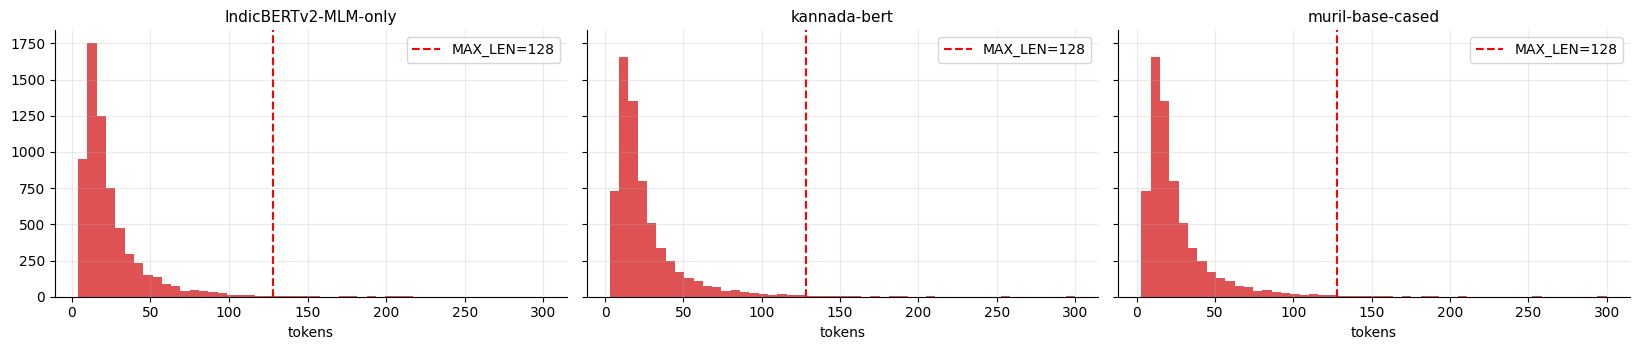

In [7]:
sample = DATASETS[TASKS[0]]["train"]["text"].tolist()
n_words = sum(len(t.split()) for t in sample)
cov, fig_data = [], {}
for m in MODELS:
    try:
        tok = AutoTokenizer.from_pretrained(m)
        ids = tok(sample, add_special_tokens=True, truncation=False)["input_ids"]
        lens = np.array([len(x) for x in ids]); tot = lens.sum()
        unk = tok.unk_token_id
        unk_rate = (sum(int((np.array(x) == unk).sum()) for x in ids) / tot) if unk is not None else float("nan")
        cov.append(dict(model=m, vocab=len(tok), truncated_pct=100 * (lens > MAX_LEN).mean(),
                        unk_pct=100 * unk_rate, tokens_per_word=tot / n_words, median_len=int(np.median(lens))))
        fig_data[m] = lens
    except Exception as e:
        print("tokenizer check failed for", m, type(e).__name__, e)
display(pd.DataFrame(cov).round(2).set_index("model"))
if fig_data:
    fig, axes = plt.subplots(1, len(fig_data), figsize=(5.5 * len(fig_data), 3.6), sharey=True); axes = np.atleast_1d(axes)
    for ax, (m, lens) in zip(axes, fig_data.items()):
        ax.hist(np.clip(lens, 0, 300), bins=50, color=PALETTE[len(ax.figure.axes) % 10], alpha=0.8)
        ax.axvline(MAX_LEN, color="red", ls="--", label=f"MAX_LEN={MAX_LEN}"); ax.legend(); ax.set_title(short(m)); ax.set_xlabel("tokens")
    savefig("tokenizer_length_distributions")

## 6. Training utilities

In [8]:
class DS(Dataset):
    def __init__(self, texts, tok, labels=None):
        enc = tok(list(texts), truncation=True, max_length=MAX_LEN)
        self.ids, self.mask, self.labels = enc["input_ids"], enc["attention_mask"], labels
    def __len__(self): return len(self.ids)
    def __getitem__(self, i):
        item = {"input_ids": self.ids[i], "attention_mask": self.mask[i]}
        if self.labels is not None: item["labels"] = int(self.labels[i])
        return item

def make_loader(texts, tok, labels=None, shuffle=False):
    def collate(batch):
        ys = [b.pop("labels") for b in batch] if "labels" in batch[0] else None
        out = tok.pad(batch, return_tensors="pt")
        out = {k: v for k, v in out.items() if k in ("input_ids", "attention_mask")}
        if ys is not None: out["labels"] = torch.tensor(ys)
        return out
    return DataLoader(DS(texts, tok, labels), batch_size=BATCH_SIZE if shuffle else BATCH_SIZE * 2,
                      shuffle=shuffle, collate_fn=collate)

@torch.no_grad()
def predict_proba(model, loader):
    model.eval(); outs = []
    for b in loader:
        b = {k: v.to(DEVICE) for k, v in b.items() if k != "labels"}
        with torch.autocast("cuda", dtype=torch.float16, enabled=USE_AMP):
            logits = model(**b).logits
        outs.append(torch.softmax(logits.float(), -1).cpu().numpy())
    return np.concatenate(outs)

def train_and_predict(model_name, n_labels, tr_texts, tr_y, test_texts, val_texts=None, val_y=None,
                      epochs=EPOCHS, lr=LR, class_weights=None):
    """Fine-tunes one model. With validation data: keeps the best-macro-F1 epoch (val+test probs captured
    at that epoch). Without: trains for `epochs` and uses the last epoch."""
    seed_everything(SEED); t_start = time.time()
    tok = AutoTokenizer.from_pretrained(model_name)
    model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=n_labels).to(DEVICE)
    tr_loader = make_loader(tr_texts, tok, tr_y, shuffle=True)
    te_loader = make_loader(test_texts, tok)
    va_loader = make_loader(val_texts, tok) if val_texts is not None else None

    no_decay = ("bias", "LayerNorm.weight")
    params = [{"params": [p for n, p in model.named_parameters() if not any(k in n for k in no_decay)], "weight_decay": WEIGHT_DECAY},
              {"params": [p for n, p in model.named_parameters() if any(k in n for k in no_decay)], "weight_decay": 0.0}]
    opt = torch.optim.AdamW(params, lr=lr)
    total = len(tr_loader) * epochs
    sched = get_linear_schedule_with_warmup(opt, int(WARMUP * total), total)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    w = torch.tensor(class_weights, dtype=torch.float, device=DEVICE) if class_weights is not None else None
    loss_fn = nn.CrossEntropyLoss(weight=w)

    best = dict(f1=-1, epoch=0, val_proba=None, test_proba=None)
    history, bad = [], 0
    for ep in range(1, epochs + 1):
        model.train(); t0 = time.time(); run = 0.0
        for b in tr_loader:
            b = {k: v.to(DEVICE) for k, v in b.items()}
            y = b.pop("labels")
            with torch.autocast("cuda", dtype=torch.float16, enabled=USE_AMP):
                logits = model(**b).logits
            loss = loss_fn(logits.float(), y)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            run += loss.item()
        rec = dict(epoch=ep, train_loss=run / len(tr_loader), secs=round(time.time() - t0))
        if va_loader is not None:
            vp = predict_proba(model, va_loader); pred = vp.argmax(1)
            rec.update(val_macro_f1=f1_score(val_y, pred, average="macro", zero_division=0),
                       val_acc=accuracy_score(val_y, pred))
            if rec["val_macro_f1"] > best["f1"]:
                best = dict(f1=rec["val_macro_f1"], epoch=ep, val_proba=vp, test_proba=predict_proba(model, te_loader)); bad = 0
            else:
                bad += 1
        history.append(rec)
        print("  ", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in rec.items()})
        if va_loader is not None and bad >= PATIENCE:
            print("   early stop"); break
    if va_loader is None:
        best = dict(f1=None, epoch=epochs, val_proba=None, test_proba=predict_proba(model, te_loader))
    del model, opt, scaler; gc.collect(); torch.cuda.empty_cache()
    best["history"] = history; best["secs"] = round(time.time() - t_start)
    return best

def slug(m): return m.replace("/", "__")

def out_labels(tk):
    labels = list(TASK_CFG[tk]["labels"])
    return [NON_HATE_LABEL if l == "Non-Hate" else l for l in labels] if tk == "A" else labels

def write_predictions(proba, test_df, tk, folder):
    c = TASK_CFG[tk]; labels = out_labels(tk)
    os.makedirs(folder, exist_ok=True)
    sub = pd.DataFrame({"id": test_df["id"].values, "label": [labels[i] for i in proba.argmax(1)]})
    path = os.path.join(folder, "predictions.csv")
    sub.to_csv(path, index=False, encoding="utf-8")
    with zipfile.ZipFile(os.path.join(folder, f"{c['name']}_predictions.zip"), "w", zipfile.ZIP_DEFLATED) as z:
        z.write(path, "predictions.csv")      # flat zip: only predictions.csv
    return sub, path

def check_submission(path, test_df, tk):
    s = pd.read_csv(path)
    assert list(s.columns) == ["id", "label"], s.columns
    assert len(s) == len(test_df) and set(s["id"]) == set(test_df["id"]) and s["id"].is_unique, "id mismatch"
    assert set(s["label"]) <= set(out_labels(tk)), set(s["label"]) - set(out_labels(tk))
    return True

def report_figure(model_name, tk, yv, vproba, history, test_proba, best_epoch):
    """Per model x task dashboard: curves, confusion (counts + normalised), per-class P/R/F1, confidence, ROC / label shares."""
    labels = TASK_CFG[tk]["labels"]; n = len(labels); pv = vproba.argmax(1); idx = list(range(n))
    fig, axes = plt.subplots(2, 3, figsize=(19, 10.5))
    h = pd.DataFrame(history); ax = axes[0, 0]
    l1 = ax.plot(h.epoch, h.train_loss, "o-", color="tab:red", label="train loss")
    ax.set_xlabel("epoch"); ax.set_ylabel("loss"); ax2 = ax.twinx(); ax2.grid(False)
    l2 = ax2.plot(h.epoch, h.val_macro_f1, "s-", color="tab:blue", label="val macro-F1")
    l3 = ax2.plot(h.epoch, h.val_acc, "^--", color="tab:green", label="val acc"); ax2.set_ylabel("score")
    ax.axvline(best_epoch, color="gray", ls=":"); ax.set_title(f"Training curves (best epoch {best_epoch})")
    ax.legend(l1 + l2 + l3, [l.get_label() for l in l1 + l2 + l3], loc="center right", fontsize=8)
    cm = confusion_matrix(yv, pv, labels=idx)
    heat(axes[0, 1], cm, labels, labels, "Confusion matrix (counts)")
    axes[0, 1].set_xlabel("predicted"); axes[0, 1].set_ylabel("true")
    heat(axes[0, 2], cm / cm.sum(1, keepdims=True), labels, labels, "Row-normalised (= per-class recall)", fmt="{:.2f}", vmin=0, vmax=1)
    axes[0, 2].set_xlabel("predicted"); axes[0, 2].set_ylabel("true")
    p, r, f, _ = precision_recall_fscore_support(yv, pv, labels=idx, zero_division=0)
    x = np.arange(n); w = 0.27
    axes[1, 0].bar(x - w, p, w, label="precision"); axes[1, 0].bar(x, r, w, label="recall"); axes[1, 0].bar(x + w, f, w, label="F1")
    axes[1, 0].set_xticks(x); axes[1, 0].set_xticklabels(labels, rotation=30, ha="right"); axes[1, 0].set_ylim(0, 1.05)
    axes[1, 0].legend(fontsize=8); axes[1, 0].set_title("Per-class precision / recall / F1 (val)")
    conf = vproba.max(1); ok = pv == yv
    axes[1, 1].hist(conf[ok], bins=20, range=(0, 1), alpha=0.65, color="tab:green", label=f"correct ({ok.sum()})")
    axes[1, 1].hist(conf[~ok], bins=20, range=(0, 1), alpha=0.65, color="tab:red", label=f"wrong ({(~ok).sum()})")
    axes[1, 1].set_xlabel("max softmax probability"); axes[1, 1].legend(); axes[1, 1].set_title("Prediction confidence (val)")
    if n == 2:
        fpr, tpr, _ = roc_curve(yv, vproba[:, 1]); pr, rc, _ = precision_recall_curve(yv, vproba[:, 1])
        axes[1, 2].plot(fpr, tpr, label=f"ROC AUC={auc(fpr, tpr):.3f}", color="tab:blue")
        axes[1, 2].plot(rc, pr, label=f"PR AP={average_precision_score(yv, vproba[:, 1]):.3f}", color="tab:orange")
        axes[1, 2].plot([0, 1], [0, 1], "k:", lw=1); axes[1, 2].set_xlabel("FPR / recall"); axes[1, 2].set_ylabel("TPR / precision")
        axes[1, 2].legend(); axes[1, 2].set_title("ROC and precision-recall (Hate = positive)")
    else:
        share = lambda a: np.bincount(a, minlength=n) / len(a)
        axes[1, 2].bar(x - w, share(yv), w, label="val gold"); axes[1, 2].bar(x, share(pv), w, label="val predicted")
        axes[1, 2].bar(x + w, share(test_proba.argmax(1)), w, label="test predicted")
        axes[1, 2].set_xticks(x); axes[1, 2].set_xticklabels(labels, rotation=30, ha="right"); axes[1, 2].legend(fontsize=8)
        axes[1, 2].set_title("Label share: gold vs predicted")
    fig.suptitle(f"{model_name} — Task {tk}: val macro-F1 {f1_score(yv, pv, average='macro'):.4f} | acc {accuracy_score(yv, pv):.4f}",
                 y=1.01, fontsize=14)
    savefig(f"report_{slug(model_name)}_task{tk}")

## 7. Train every model on every task
For each model x task: train -> best epoch on validation -> metrics + dashboard -> **its own** test `predictions.csv` (+ zip).


 MODEL ai4bharat/IndicBERTv2-MLM-only | TASK A (taskA_binary)


pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.12GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: ai4bharat/IndicBERTv2-MLM-only
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those p

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

   {'epoch': 1, 'train_loss': 0.6296, 'secs': 47, 'val_macro_f1': 0.7515, 'val_acc': 0.7519}
   {'epoch': 2, 'train_loss': 0.5015, 'secs': 47, 'val_macro_f1': 0.763, 'val_acc': 0.763}
   {'epoch': 3, 'train_loss': 0.3943, 'secs': 48, 'val_macro_f1': 0.7657, 'val_acc': 0.768}
   {'epoch': 4, 'train_loss': 0.3132, 'secs': 47, 'val_macro_f1': 0.7739, 'val_acc': 0.7754}
   {'epoch': 5, 'train_loss': 0.2397, 'secs': 48, 'val_macro_f1': 0.7832, 'val_acc': 0.7854}
   {'epoch': 6, 'train_loss': 0.1816, 'secs': 47, 'val_macro_f1': 0.7751, 'val_acc': 0.7754}

  >>> VALIDATION  macro-F1=0.7832  acc=0.7854  (best epoch 5)
              precision    recall  f1-score   support

    Non-Hate     0.7500    0.8686    0.8050       411
        Hate     0.8364    0.6987    0.7614       395

    accuracy                         0.7854       806
   macro avg     0.7932    0.7837    0.7832       806
weighted avg     0.7923    0.7854    0.7836       806



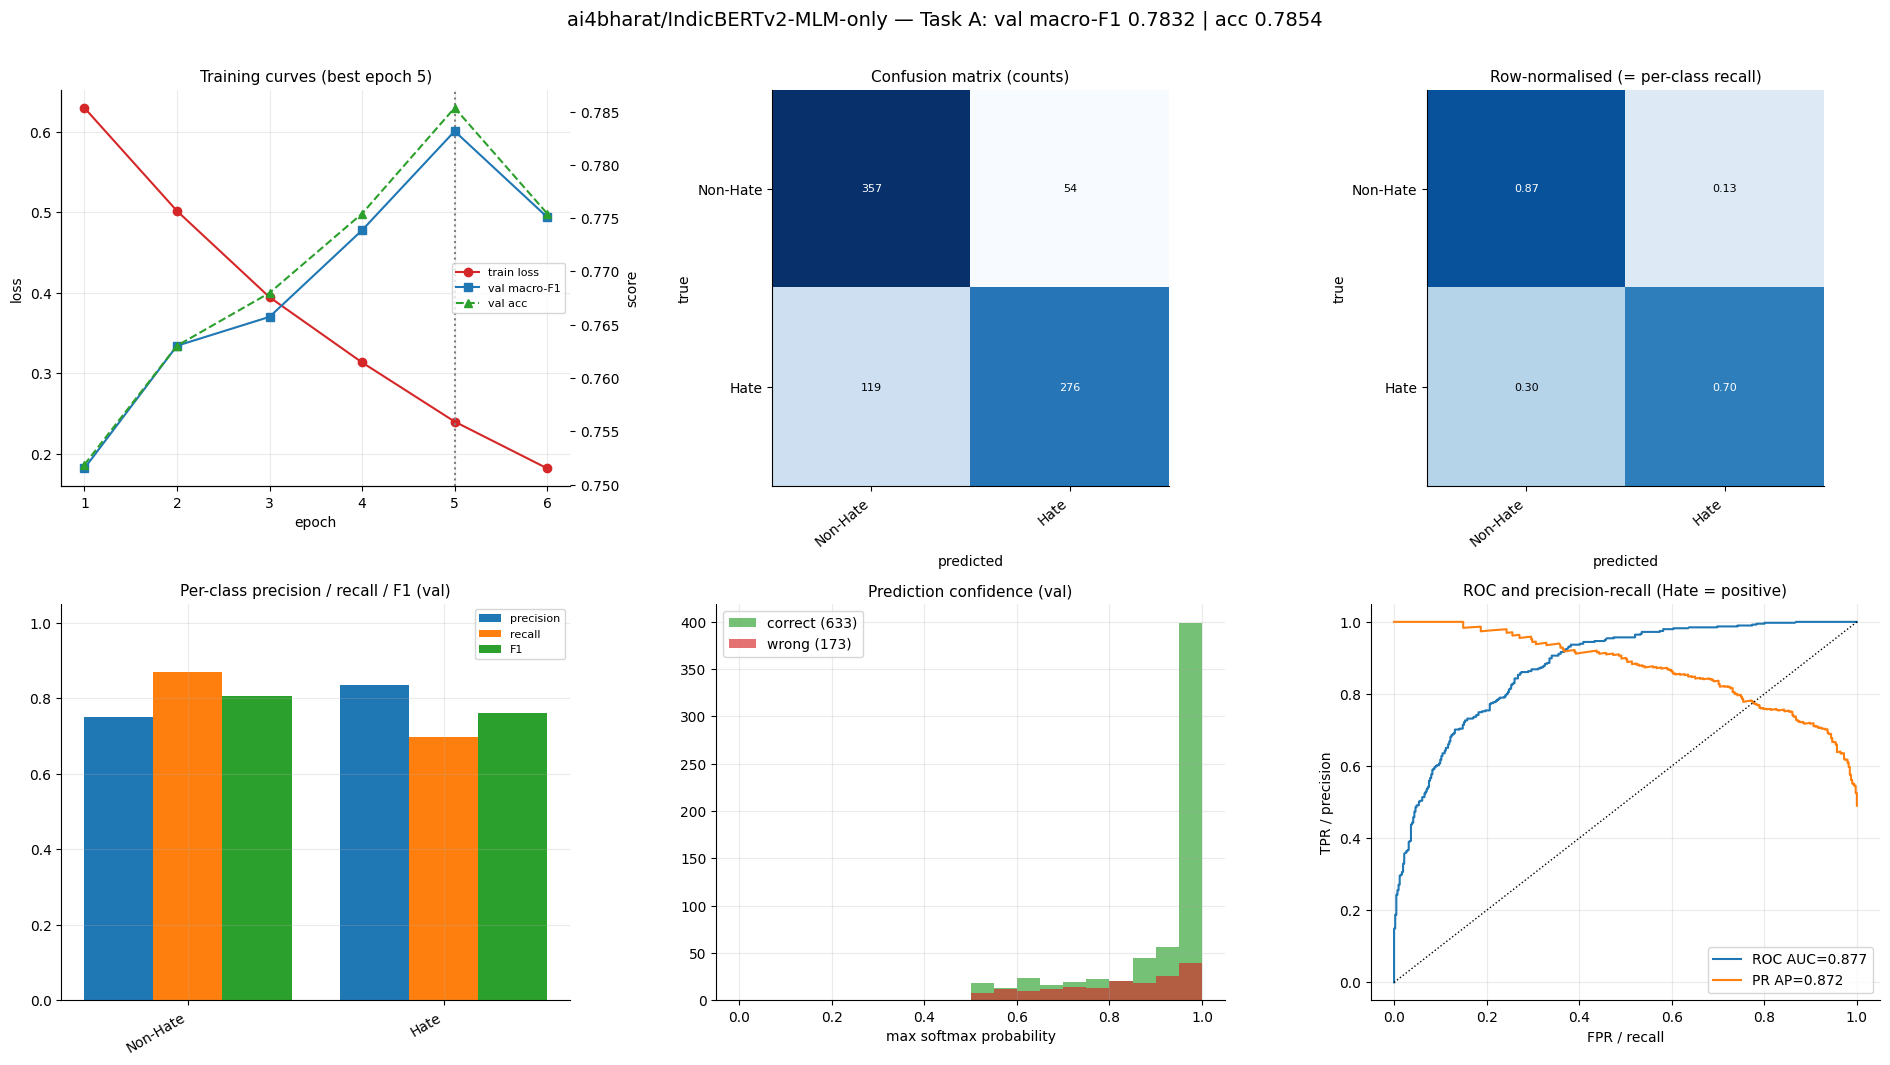

  READY TO SUBMIT -> /kaggle/working/outputs/ai4bharat__IndicBERTv2-MLM-only/taskA_binary/predictions.csv  (806 rows) | test label dist: {'Non-hate': 443, 'Hate': 363}

 MODEL ai4bharat/IndicBERTv2-MLM-only | TASK B (taskB_finegrained)
  class weights: {'Gender': np.float64(0.62), 'Political': np.float64(0.97), 'Religion': np.float64(1.17), 'Geo-political': np.float64(1.68), 'Violence': np.float64(1.54), 'Others': np.float64(1.08)}


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: ai4bharat/IndicBERTv2-MLM-only
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those p

   {'epoch': 1, 'train_loss': 1.693, 'secs': 24, 'val_macro_f1': 0.3299, 'val_acc': 0.5873}
   {'epoch': 2, 'train_loss': 1.3031, 'secs': 24, 'val_macro_f1': 0.4908, 'val_acc': 0.6506}
   {'epoch': 3, 'train_loss': 1.0299, 'secs': 24, 'val_macro_f1': 0.5113, 'val_acc': 0.6481}
   {'epoch': 4, 'train_loss': 0.8611, 'secs': 24, 'val_macro_f1': 0.5698, 'val_acc': 0.6785}
   {'epoch': 5, 'train_loss': 0.7448, 'secs': 24, 'val_macro_f1': 0.5921, 'val_acc': 0.6886}
   {'epoch': 6, 'train_loss': 0.6648, 'secs': 24, 'val_macro_f1': 0.6182, 'val_acc': 0.6987}

  >>> VALIDATION  macro-F1=0.6182  acc=0.6987  (best epoch 6)
               precision    recall  f1-score   support

       Gender     0.7526    0.8412    0.7944       170
    Political     0.8143    0.8143    0.8143        70
     Religion     0.8158    0.6458    0.7209        48
Geo-political     0.5600    0.6087    0.5833        23
     Violence     0.4074    0.3929    0.4000        28
       Others     0.4444    0.3571    0.3960     

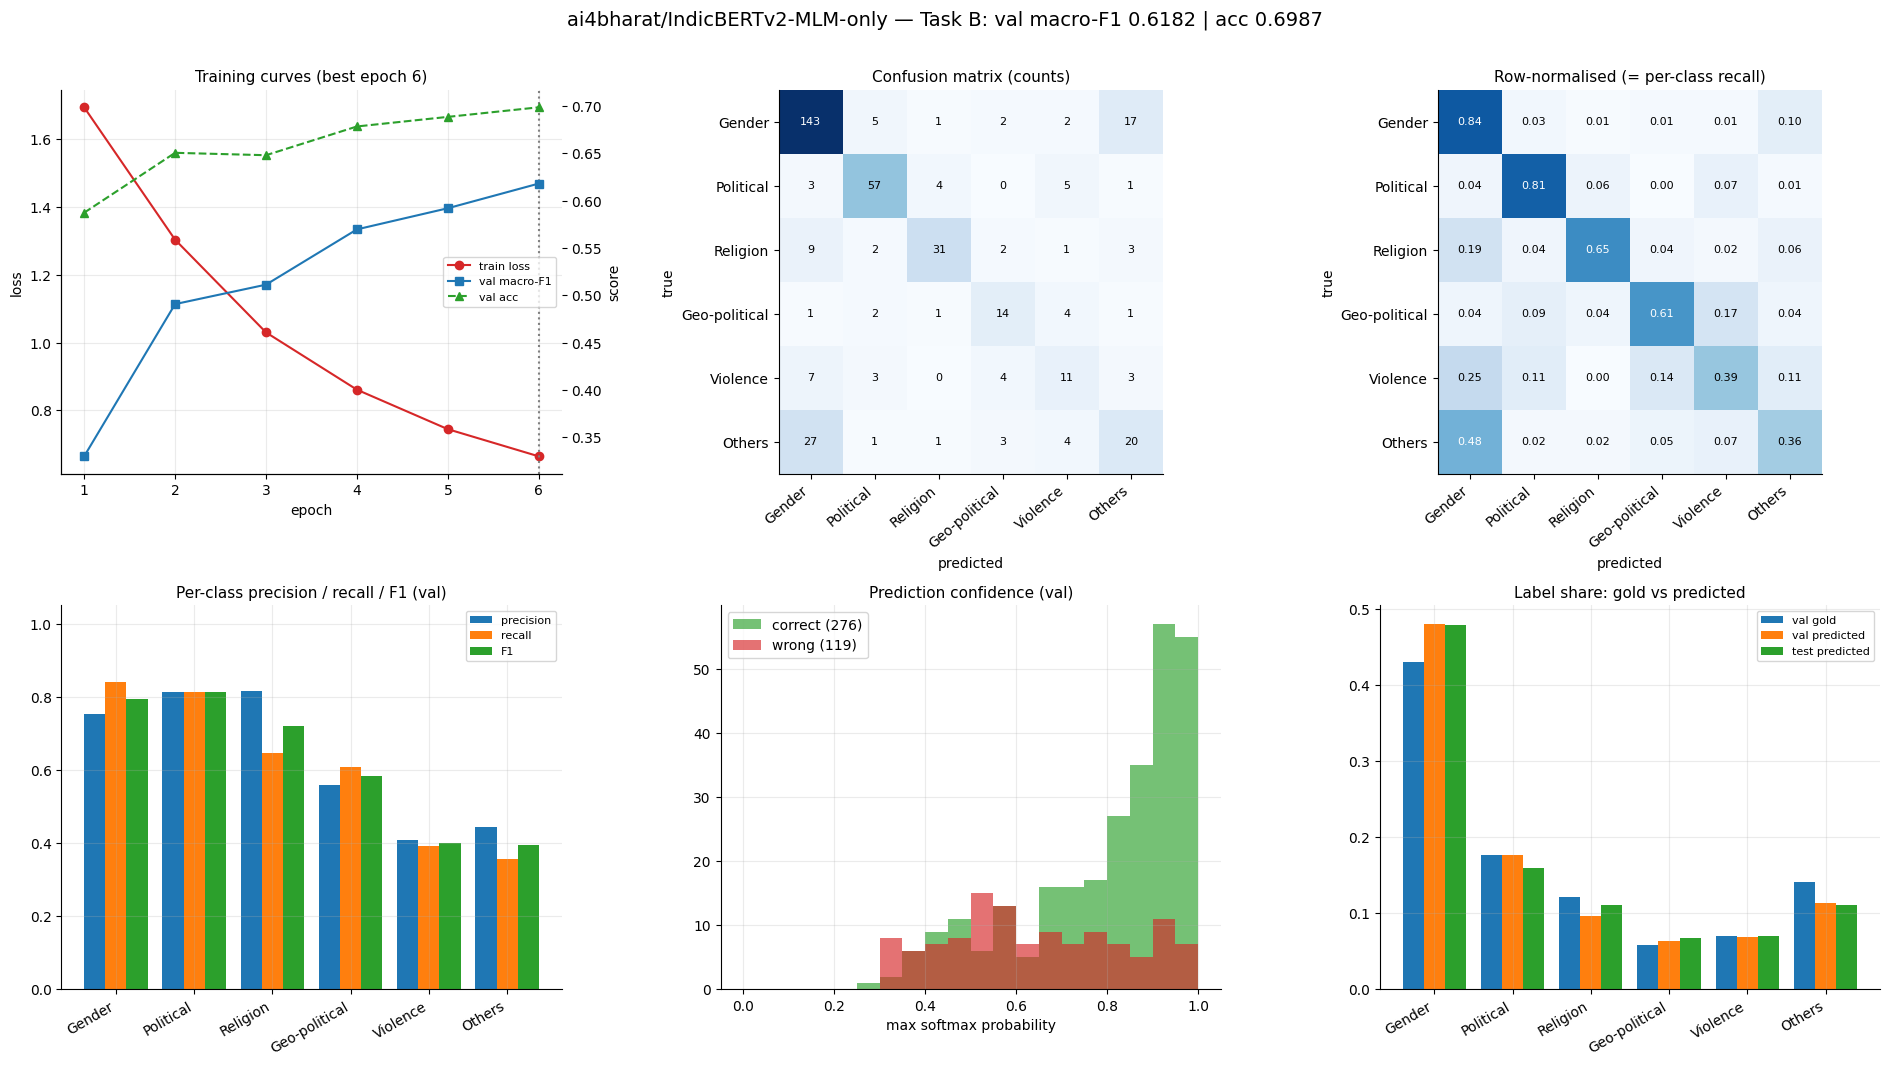

  READY TO SUBMIT -> /kaggle/working/outputs/ai4bharat__IndicBERTv2-MLM-only/taskB_finegrained/predictions.csv  (396 rows) | test label dist: {'Gender': 190, 'Political': 63, 'Religion': 44, 'Others': 44, 'Violence': 28, 'Geo-political': 27}

 MODEL l3cube-pune/kannada-bert | TASK A (taskA_binary)


model.safetensors: reconstructing file:   0%|          |  0.00B /  951MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: l3cube-pune/kannada-bert
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
bert.pooler.dense.weight                   | MISSING    | 
bert.pooler.dense.bias                     | MISSING    | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


   {'epoch': 1, 'train_loss': 0.6552, 'secs': 45, 'val_macro_f1': 0.7343, 'val_acc': 0.7357}
   {'epoch': 2, 'train_loss': 0.5305, 'secs': 44, 'val_macro_f1': 0.7723, 'val_acc': 0.773}
   {'epoch': 3, 'train_loss': 0.4144, 'secs': 45, 'val_macro_f1': 0.7845, 'val_acc': 0.7854}
   {'epoch': 4, 'train_loss': 0.3127, 'secs': 45, 'val_macro_f1': 0.7948, 'val_acc': 0.7953}
   {'epoch': 5, 'train_loss': 0.2468, 'secs': 44, 'val_macro_f1': 0.8052, 'val_acc': 0.8052}
   {'epoch': 6, 'train_loss': 0.2055, 'secs': 44, 'val_macro_f1': 0.8027, 'val_acc': 0.8027}

  >>> VALIDATION  macro-F1=0.8052  acc=0.8052  (best epoch 5)
              precision    recall  f1-score   support

    Non-Hate     0.8223    0.7883    0.8050       411
        Hate     0.7888    0.8228    0.8055       395

    accuracy                         0.8052       806
   macro avg     0.8056    0.8056    0.8052       806
weighted avg     0.8059    0.8052    0.8052       806



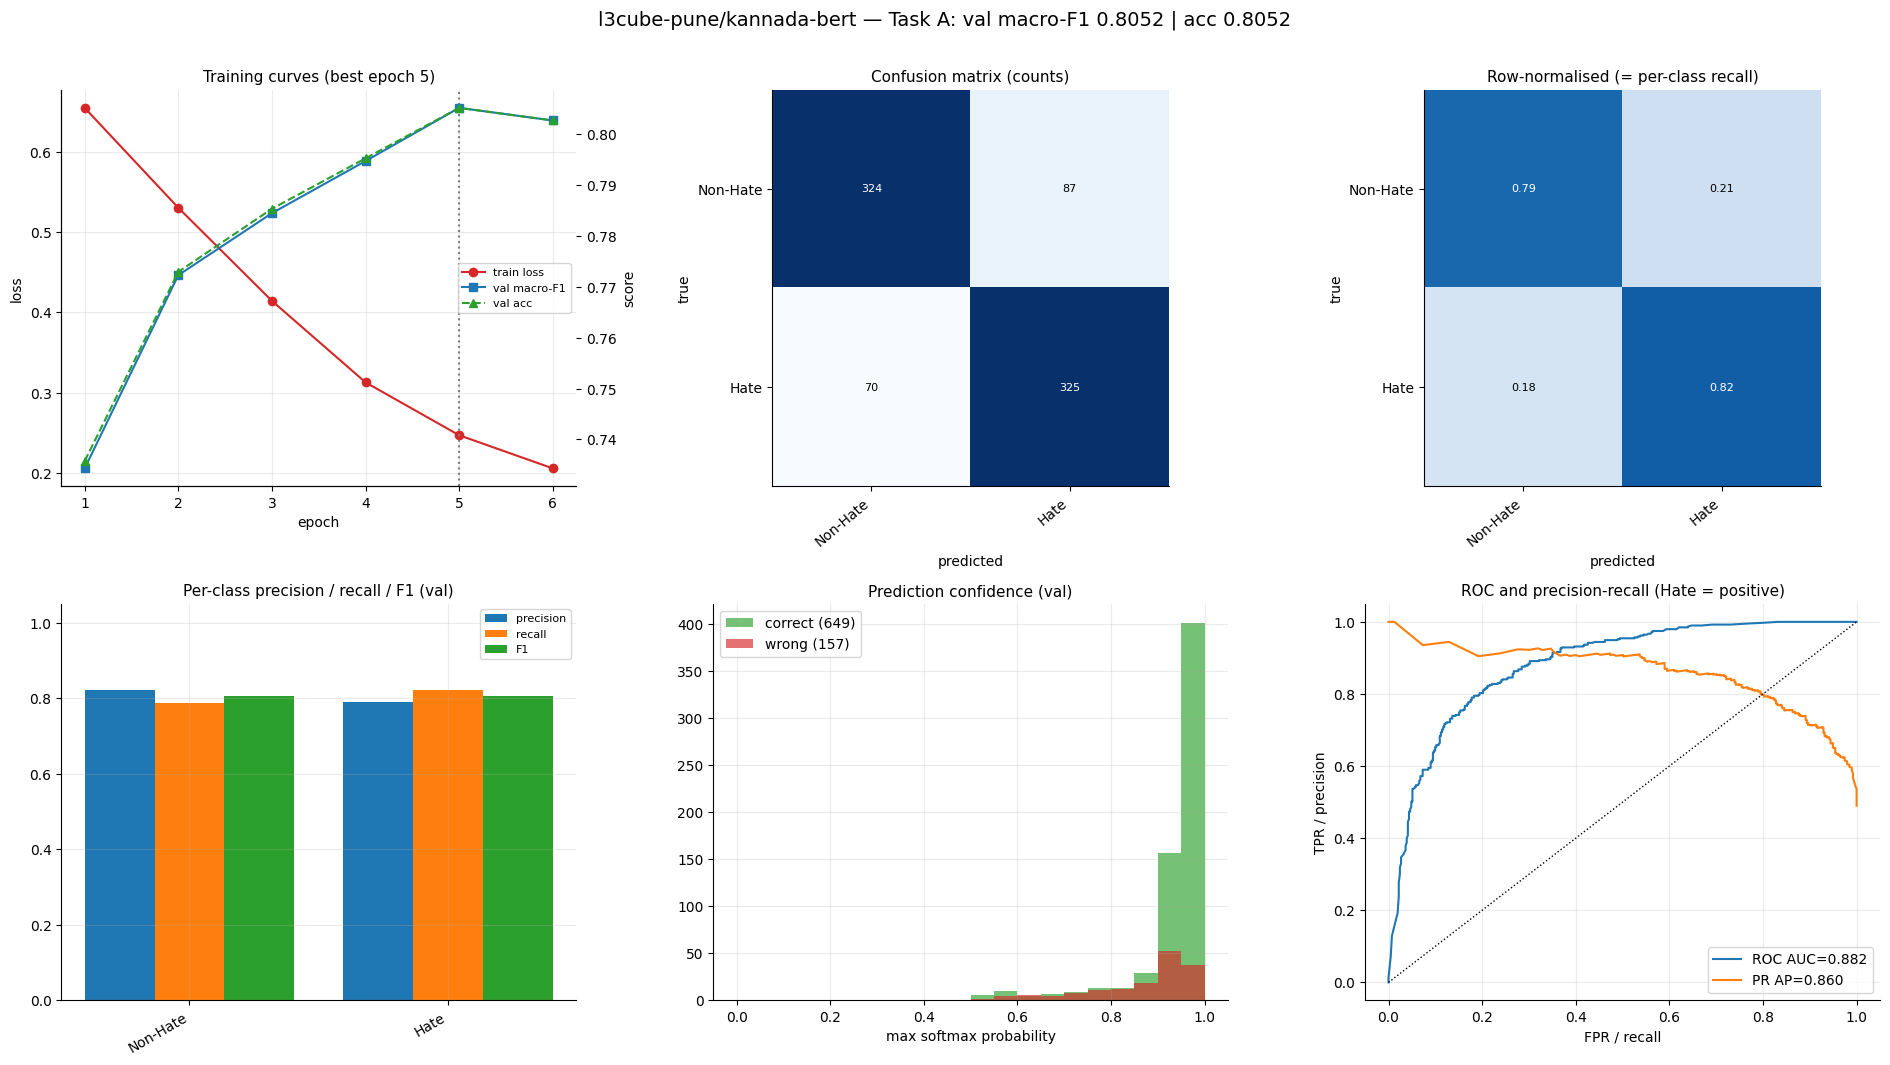

  READY TO SUBMIT -> /kaggle/working/outputs/l3cube-pune__kannada-bert/taskA_binary/predictions.csv  (806 rows) | test label dist: {'Hate': 425, 'Non-hate': 381}

 MODEL l3cube-pune/kannada-bert | TASK B (taskB_finegrained)
  class weights: {'Gender': np.float64(0.62), 'Political': np.float64(0.97), 'Religion': np.float64(1.17), 'Geo-political': np.float64(1.68), 'Violence': np.float64(1.54), 'Others': np.float64(1.08)}


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: l3cube-pune/kannada-bert
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
bert.pooler.dense.weight                   | MISSING    | 
bert.pooler.dense.bias                     | MISSING    | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


   {'epoch': 1, 'train_loss': 1.7663, 'secs': 23, 'val_macro_f1': 0.2076, 'val_acc': 0.519}
   {'epoch': 2, 'train_loss': 1.6466, 'secs': 23, 'val_macro_f1': 0.3165, 'val_acc': 0.5899}
   {'epoch': 3, 'train_loss': 1.5046, 'secs': 23, 'val_macro_f1': 0.4167, 'val_acc': 0.6203}
   {'epoch': 4, 'train_loss': 1.4039, 'secs': 23, 'val_macro_f1': 0.4025, 'val_acc': 0.6152}
   {'epoch': 5, 'train_loss': 1.3289, 'secs': 23, 'val_macro_f1': 0.4385, 'val_acc': 0.638}
   {'epoch': 6, 'train_loss': 1.2842, 'secs': 23, 'val_macro_f1': 0.4495, 'val_acc': 0.6481}

  >>> VALIDATION  macro-F1=0.4495  acc=0.6481  (best epoch 6)
               precision    recall  f1-score   support

       Gender     0.6473    0.9176    0.7591       170
    Political     0.6988    0.8286    0.7582        70
     Religion     0.6667    0.5417    0.5977        48
Geo-political     0.5000    0.6957    0.5818        23
     Violence     0.0000    0.0000    0.0000        28
       Others     0.0000    0.0000    0.0000      

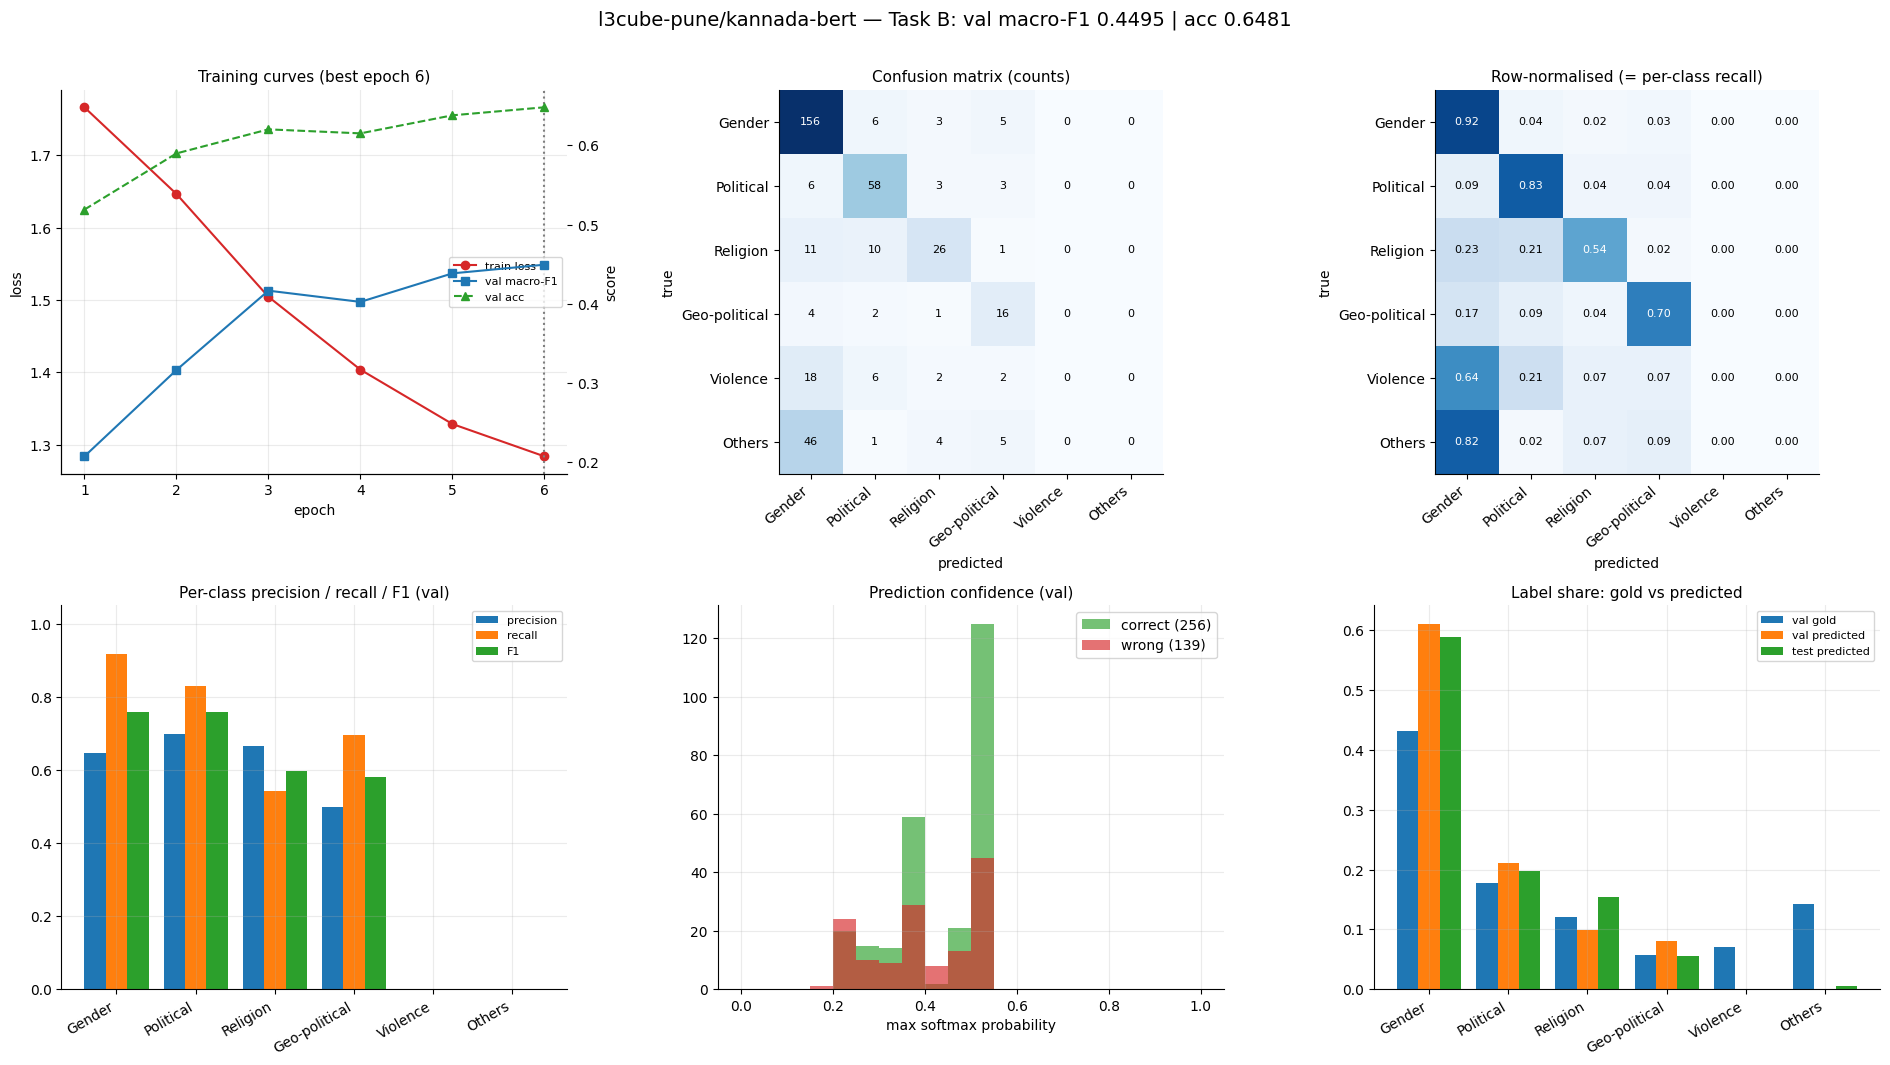

  READY TO SUBMIT -> /kaggle/working/outputs/l3cube-pune__kannada-bert/taskB_finegrained/predictions.csv  (396 rows) | test label dist: {'Gender': 233, 'Political': 78, 'Religion': 61, 'Geo-political': 22, 'Others': 2}

 MODEL google/muril-base-cased | TASK A (taskA_binary)


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  953MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google/muril-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params w

model.safetensors: reconstructing file:   0%|          |  0.00B /  953MB            

model.safetensors: downloading bytes:           |  0.00B            

   {'epoch': 1, 'train_loss': 0.661, 'secs': 45, 'val_macro_f1': 0.7457, 'val_acc': 0.7457}
   {'epoch': 2, 'train_loss': 0.526, 'secs': 44, 'val_macro_f1': 0.7938, 'val_acc': 0.794}
   {'epoch': 3, 'train_loss': 0.4015, 'secs': 44, 'val_macro_f1': 0.8212, 'val_acc': 0.8213}
   {'epoch': 4, 'train_loss': 0.3061, 'secs': 44, 'val_macro_f1': 0.8212, 'val_acc': 0.8213}
   {'epoch': 5, 'train_loss': 0.2445, 'secs': 45, 'val_macro_f1': 0.8142, 'val_acc': 0.8151}
   {'epoch': 6, 'train_loss': 0.2032, 'secs': 44, 'val_macro_f1': 0.8189, 'val_acc': 0.8189}

  >>> VALIDATION  macro-F1=0.8212  acc=0.8213  (best epoch 4)
              precision    recall  f1-score   support

    Non-Hate     0.8217    0.8297    0.8257       411
        Hate     0.8210    0.8127    0.8168       395

    accuracy                         0.8213       806
   macro avg     0.8213    0.8212    0.8212       806
weighted avg     0.8213    0.8213    0.8213       806



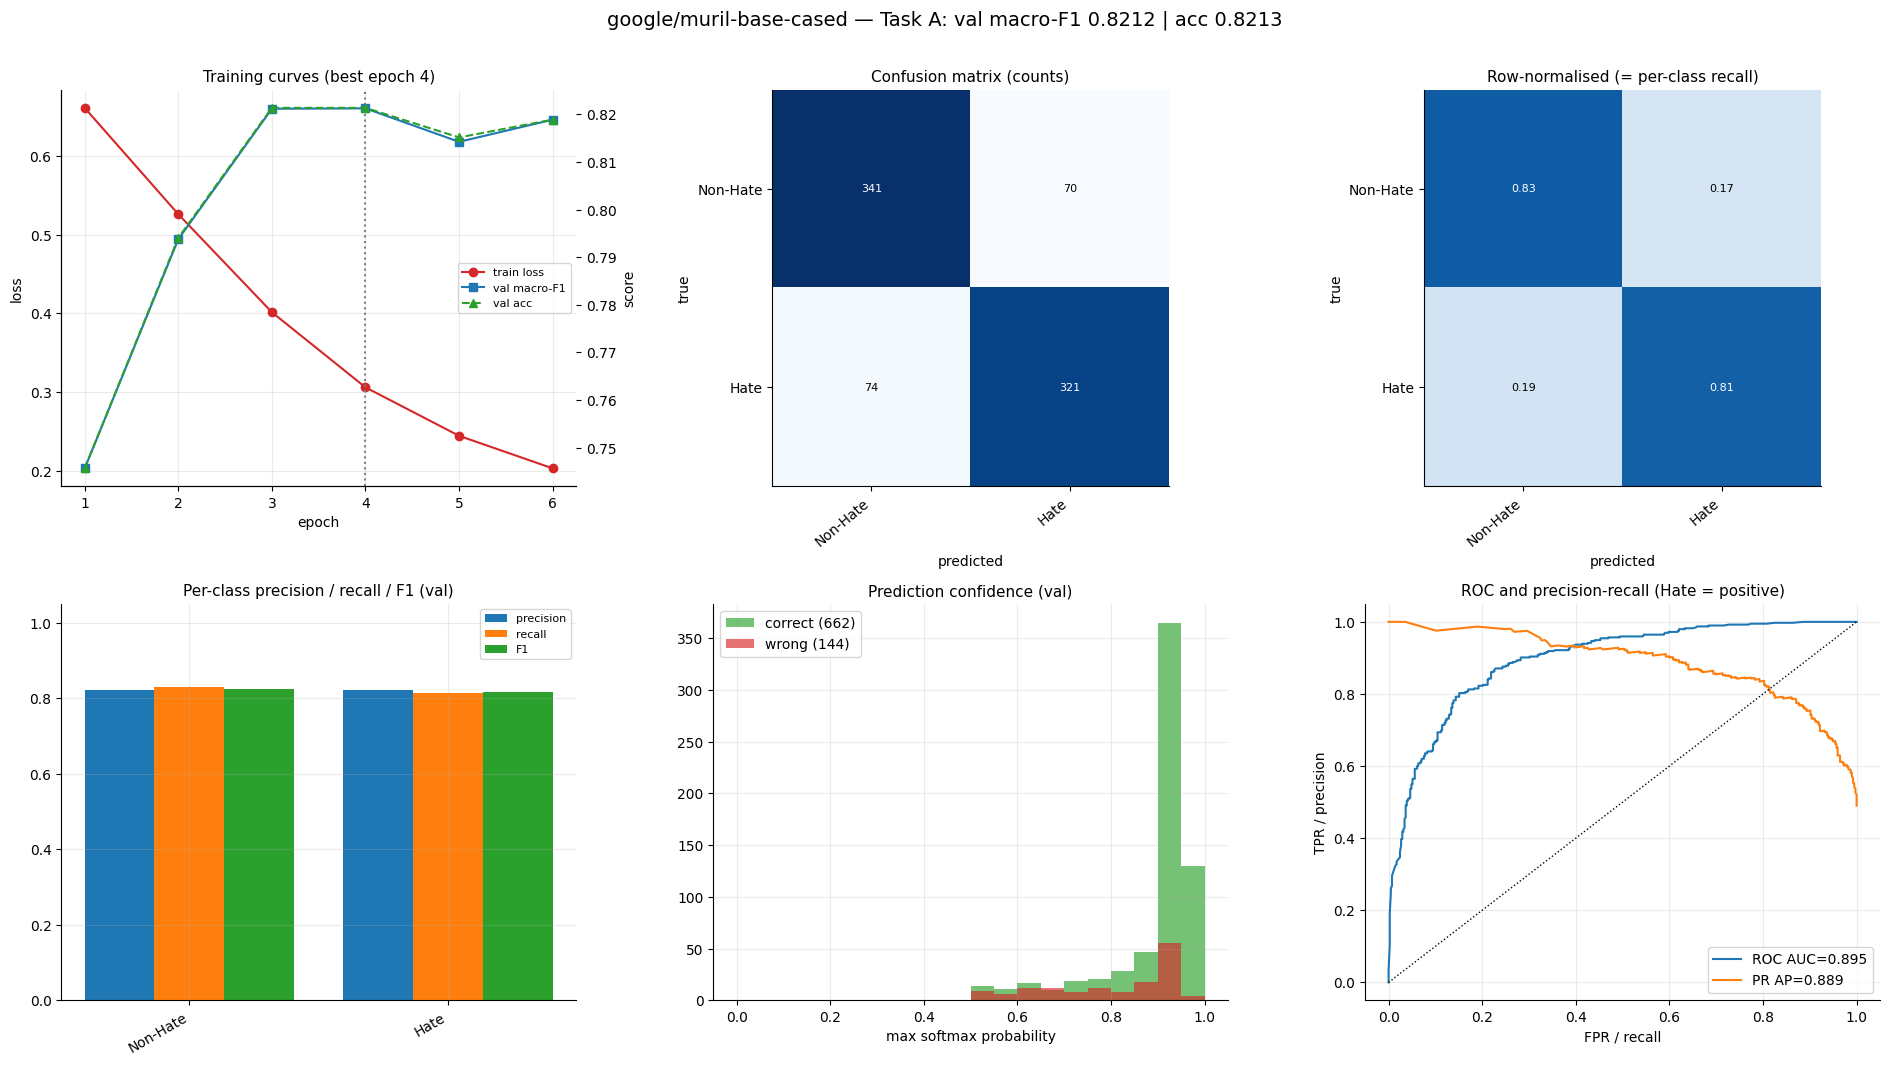

  READY TO SUBMIT -> /kaggle/working/outputs/google__muril-base-cased/taskA_binary/predictions.csv  (806 rows) | test label dist: {'Hate': 410, 'Non-hate': 396}

 MODEL google/muril-base-cased | TASK B (taskB_finegrained)
  class weights: {'Gender': np.float64(0.62), 'Political': np.float64(0.97), 'Religion': np.float64(1.17), 'Geo-political': np.float64(1.68), 'Violence': np.float64(1.54), 'Others': np.float64(1.08)}


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google/muril-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params w

   {'epoch': 1, 'train_loss': 1.7723, 'secs': 23, 'val_macro_f1': 0.1003, 'val_acc': 0.4304}
   {'epoch': 2, 'train_loss': 1.6638, 'secs': 23, 'val_macro_f1': 0.3195, 'val_acc': 0.6}
   {'epoch': 3, 'train_loss': 1.5498, 'secs': 22, 'val_macro_f1': 0.3184, 'val_acc': 0.6}
   {'epoch': 4, 'train_loss': 1.4631, 'secs': 22, 'val_macro_f1': 0.3213, 'val_acc': 0.5975}
   {'epoch': 5, 'train_loss': 1.3976, 'secs': 22, 'val_macro_f1': 0.3184, 'val_acc': 0.5949}
   {'epoch': 6, 'train_loss': 1.3607, 'secs': 23, 'val_macro_f1': 0.3764, 'val_acc': 0.6228}

  >>> VALIDATION  macro-F1=0.3764  acc=0.6228  (best epoch 6)
               precision    recall  f1-score   support

       Gender     0.6324    0.9412    0.7565       170
    Political     0.6786    0.8143    0.7403        70
     Religion     0.5319    0.5208    0.5263        48
Geo-political     0.3636    0.1739    0.2353        23
     Violence     0.0000    0.0000    0.0000        28
       Others     0.0000    0.0000    0.0000        56

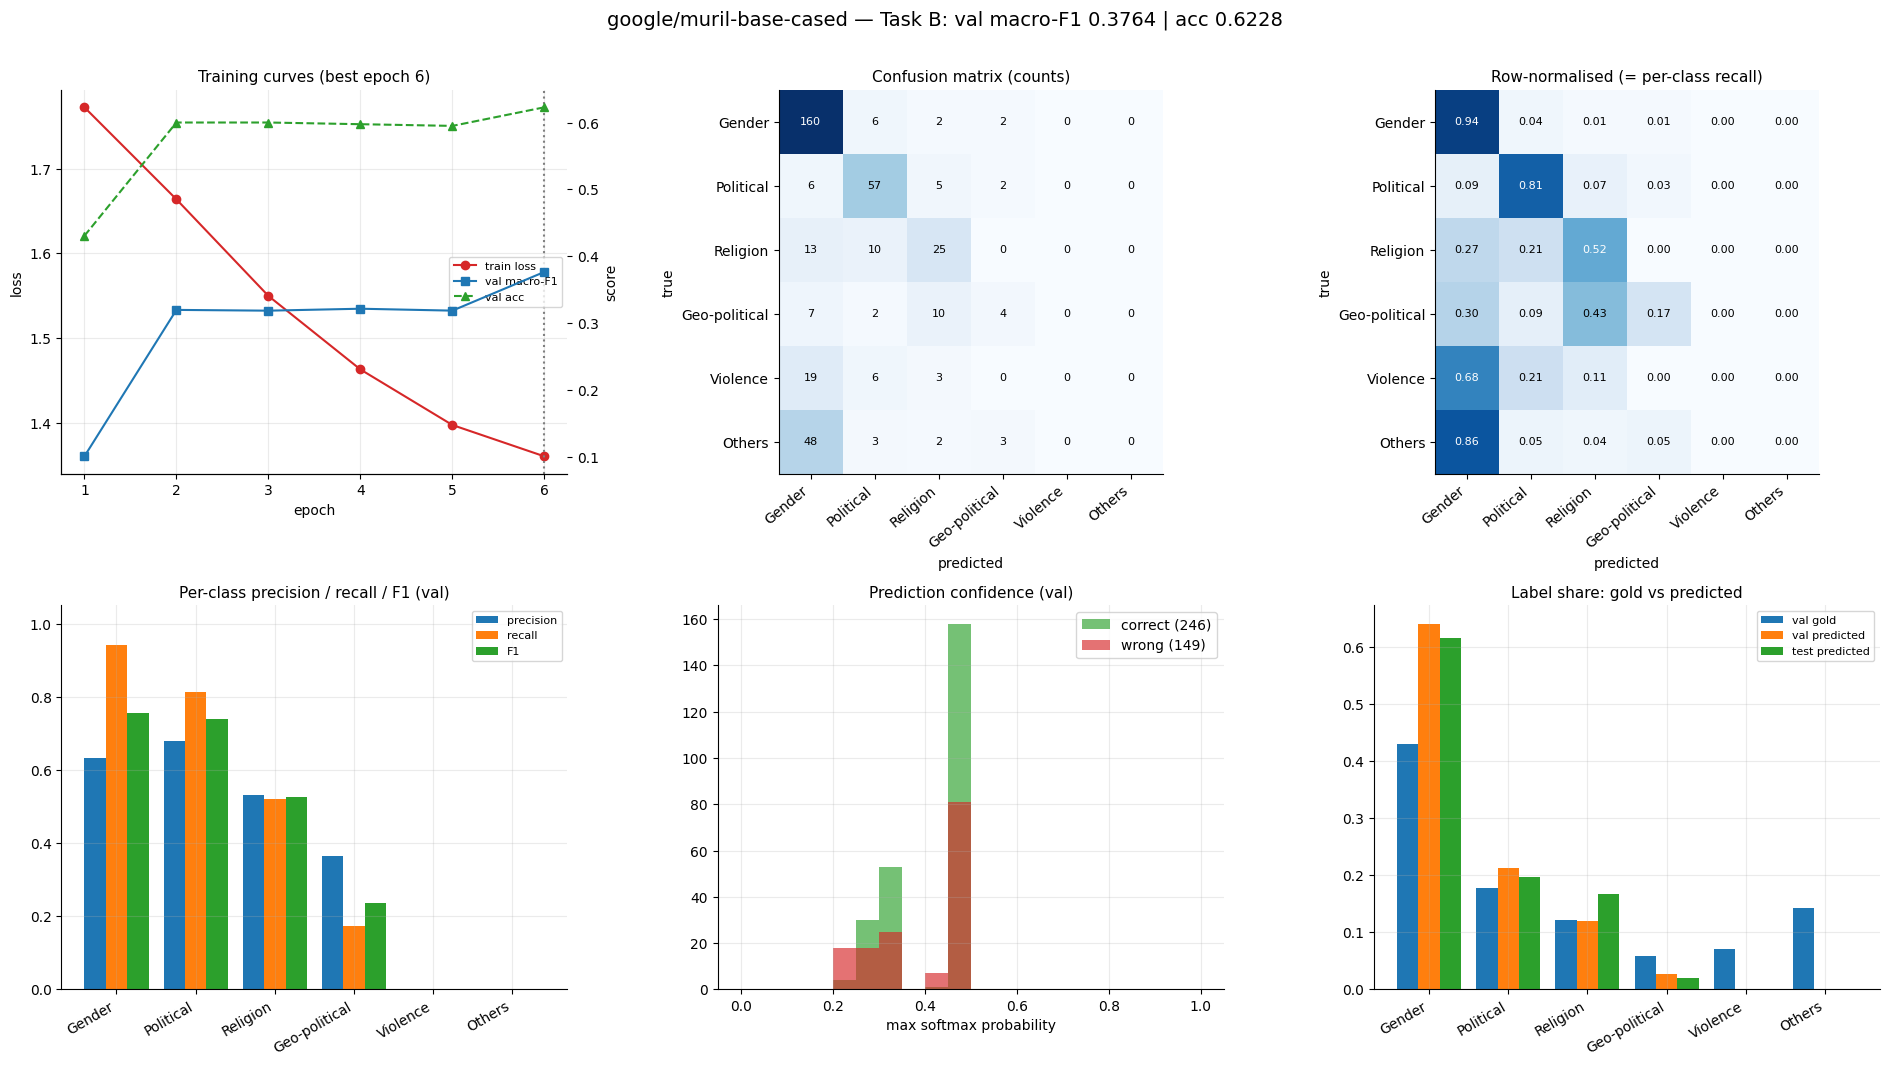

  READY TO SUBMIT -> /kaggle/working/outputs/google__muril-base-cased/taskB_finegrained/predictions.csv  (396 rows) | test label dist: {'Gender': 244, 'Political': 78, 'Religion': 66, 'Geo-political': 8}


In [9]:
RESULTS, STORE = [], {}     # STORE[(model, task)] = dict(val_proba, test_proba, history, ...)

for model_name in MODELS:
    for tk in TASKS:
        cfg, d = TASK_CFG[tk], DATASETS[tk]
        n_labels = len(cfg["labels"])
        print("\n" + "=" * 90 + f"\n MODEL {model_name} | TASK {tk} ({cfg['name']})\n" + "=" * 90)

        cw = None
        if tk == "B" and USE_CLASS_WEIGHTS_B:
            cnt = np.bincount(d["train"]["y"], minlength=n_labels).astype(float)
            cw = (cnt.sum() / (n_labels * cnt)) ** 0.5
            print("  class weights:", dict(zip(cfg["labels"], cw.round(2))))

        lr = LR_OVERRIDE.get(model_name, LR)
        try:
            r = train_and_predict(model_name, n_labels, d["train"]["text"], d["train"]["y"].values,
                                  d["test"]["text"], d["val"]["text"], d["val"]["y"].values,
                                  lr=lr, class_weights=cw)
        except Exception as e:
            print(f"  !! FAILED {model_name} task {tk}: {type(e).__name__}: {e}")
            gc.collect(); torch.cuda.empty_cache()
            continue

        test_proba, secs = r["test_proba"], r["secs"]
        if RETRAIN_ON_TRAIN_PLUS_VAL:
            print(f"  retraining on train+val for {r['epoch']} epochs ...")
            full = pd.concat([d["train"], d["val"]])
            rr = train_and_predict(model_name, n_labels, full["text"], full["y"].values, d["test"]["text"],
                                   epochs=r["epoch"], lr=lr, class_weights=cw)
            test_proba, secs = rr["test_proba"], secs + rr["secs"]

        # ---- validation metrics (best epoch)
        yv, pv = d["val"]["y"].values, r["val_proba"].argmax(1)
        print(f"\n  >>> VALIDATION  macro-F1={f1_score(yv, pv, average='macro'):.4f}  acc={accuracy_score(yv, pv):.4f}  (best epoch {r['epoch']})")
        print(classification_report(yv, pv, labels=list(range(n_labels)), target_names=cfg["labels"], digits=4, zero_division=0))
        report_figure(model_name, tk, yv, r["val_proba"], r["history"], test_proba, r["epoch"])

        # ---- this model's own test predictions (one submission per model per task)
        folder = os.path.join(OUT_DIR, slug(model_name), cfg["name"])
        sub, path = write_predictions(test_proba, d["test"], tk, folder)
        check_submission(path, d["test"], tk)
        print(f"  READY TO SUBMIT -> {path}  ({len(sub)} rows) | test label dist: {sub['label'].value_counts().to_dict()}")
        np.save(os.path.join(folder, "val_proba.npy"), r["val_proba"]); np.save(os.path.join(folder, "test_proba.npy"), test_proba)

        STORE[(model_name, tk)] = dict(val_proba=r["val_proba"], test_proba=test_proba, history=r["history"], best_epoch=r["epoch"], secs=secs)
        RESULTS.append(dict(model=model_name, task=tk, best_epoch=r["epoch"], val_macro_f1=f1_score(yv, pv, average="macro"),
                            val_weighted_f1=f1_score(yv, pv, average="weighted"), val_acc=accuracy_score(yv, pv), train_secs=secs))

## 8. Model comparison (side by side, nothing is merged)

In [10]:
summary = pd.DataFrame(RESULTS)
summary.to_csv(os.path.join(OUT_DIR, "results_summary.csv"), index=False)
for tk in TASKS:
    s = summary[summary.task == tk].sort_values("val_macro_f1", ascending=False)
    print(f"\nTask {tk} leaderboard (validation):")
    try: display(s.drop(columns="task").set_index("model").round(4).style.background_gradient(cmap="Greens", subset=["val_macro_f1", "val_acc"]))
    except Exception: display(s.drop(columns="task").set_index("model").round(4))


Task A leaderboard (validation):


,best_epoch,val_macro_f1,val_weighted_f1,val_acc,train_secs
model,,,,,
google/muril-base-cased,4,0.821200,0.821300,0.821300,289
l3cube-pune/kannada-bert,5,0.805200,0.805200,0.805200,295
ai4bharat/IndicBERTv2-MLM-only,5,0.783200,0.783600,0.785400,311



Task B leaderboard (validation):


,best_epoch,val_macro_f1,val_weighted_f1,val_acc,train_secs
model,,,,,
ai4bharat/IndicBERTv2-MLM-only,6,0.618200,0.692300,0.698700,155
l3cube-pune/kannada-bert,6,0.449500,0.567600,0.648100,146
google/muril-base-cased,6,0.376400,0.534400,0.622800,144


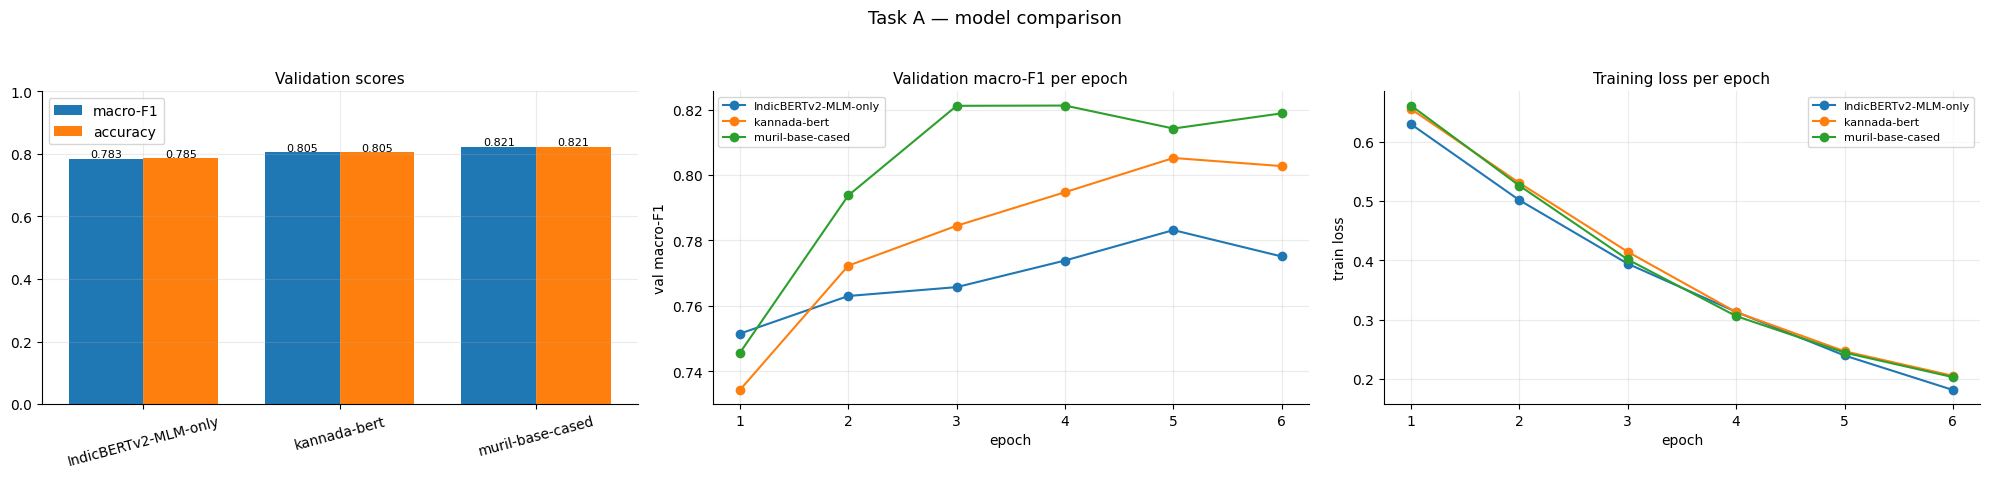

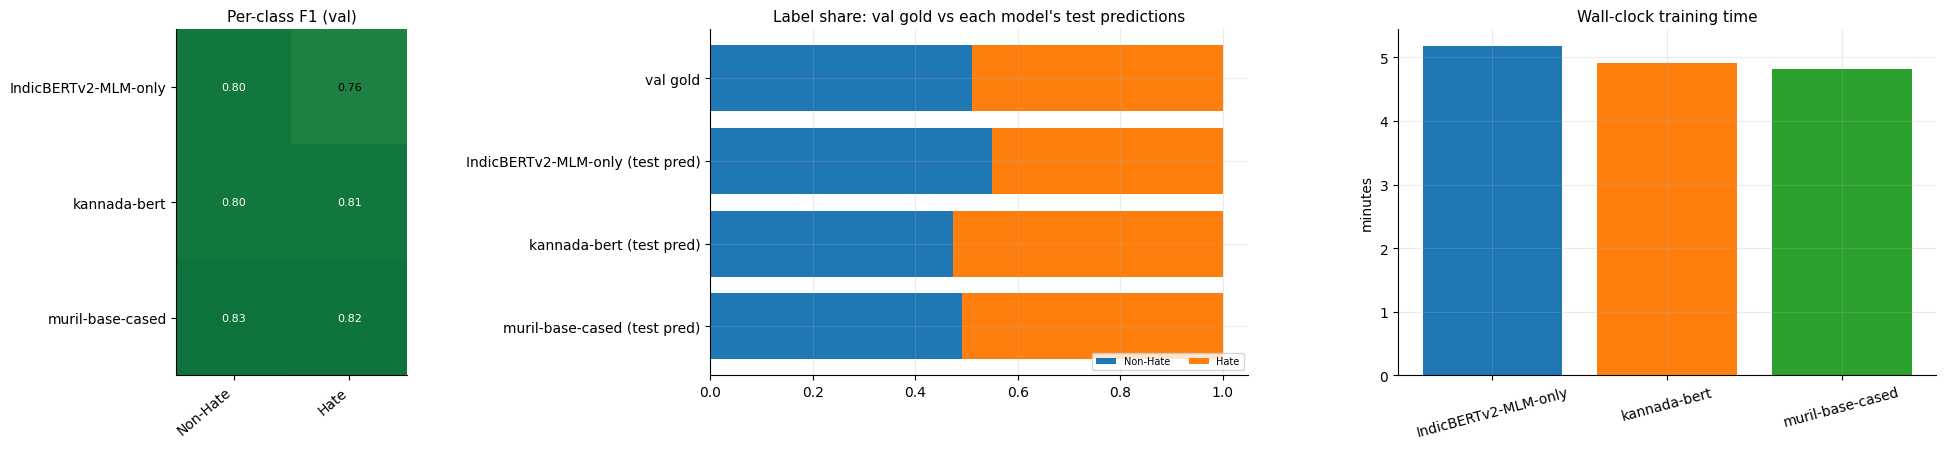

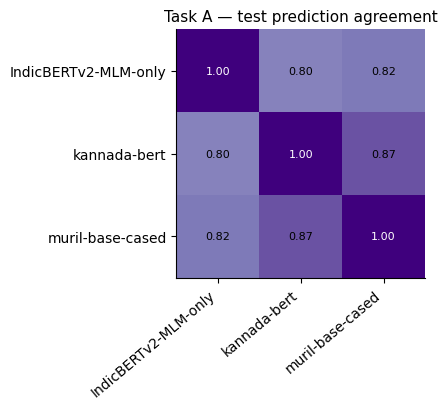

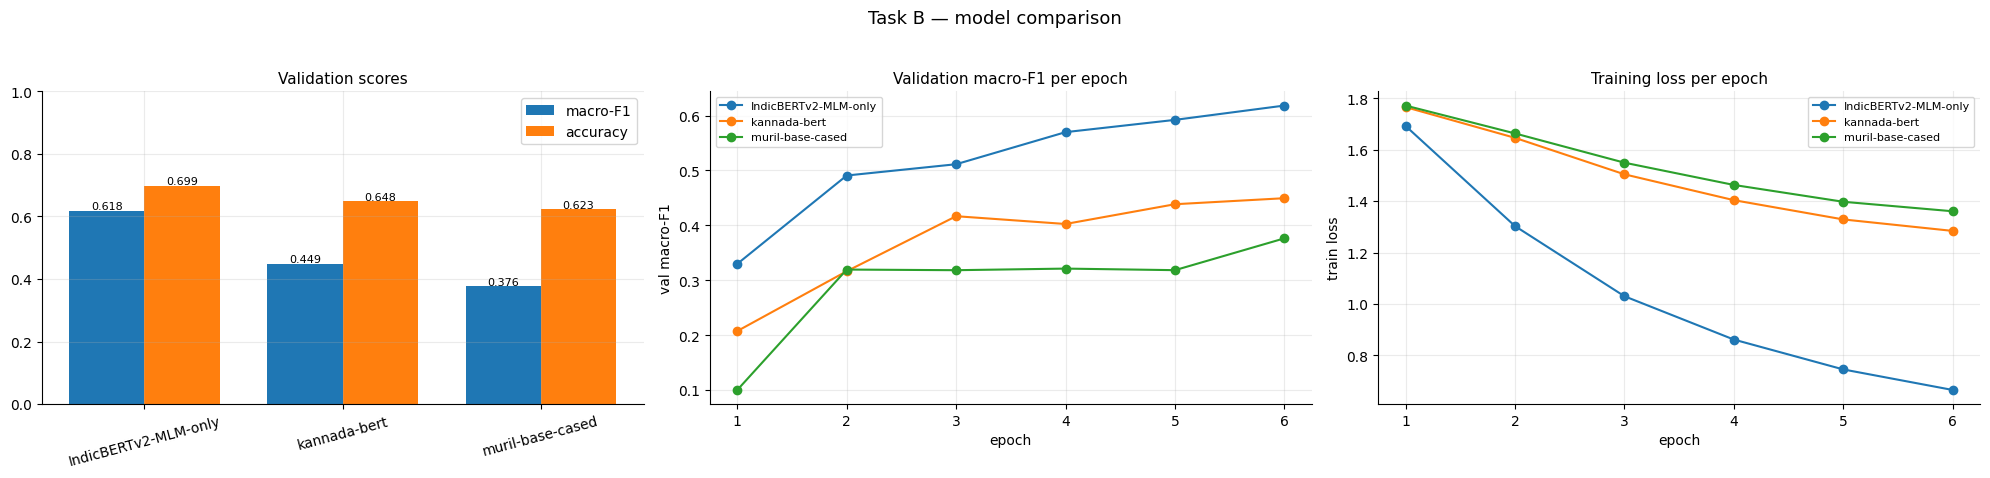

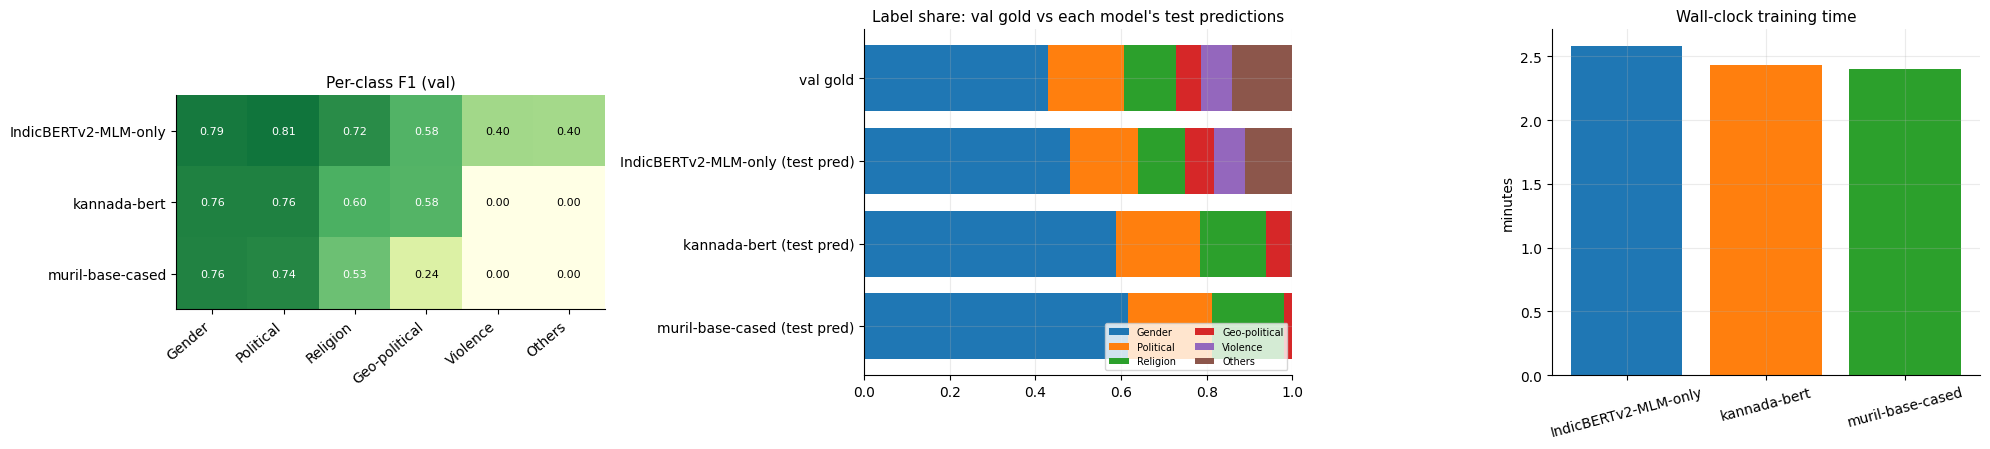

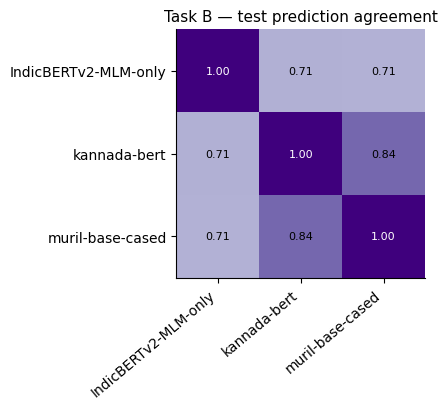

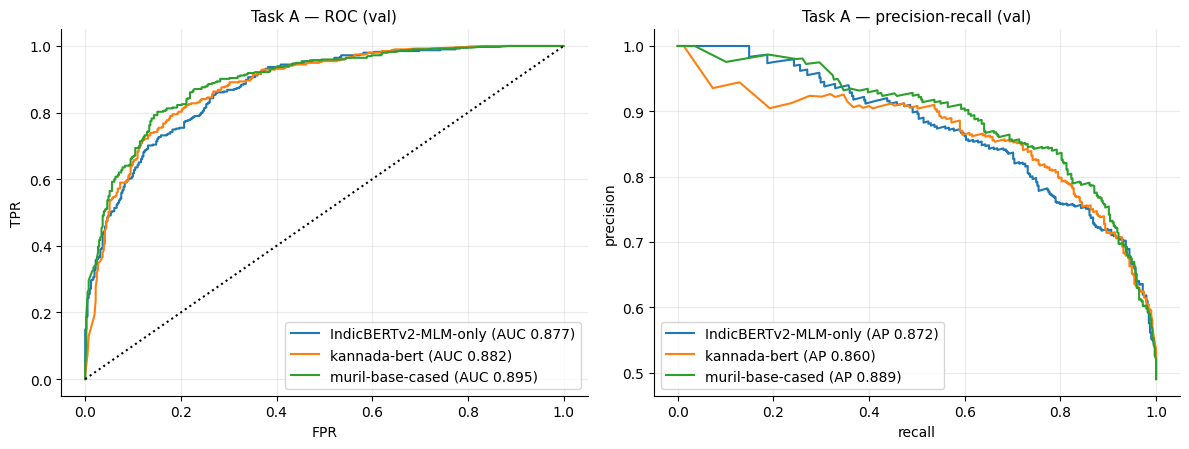

In [11]:
for tk in TASKS:
    ms = [m for m in MODELS if (m, tk) in STORE]
    if not ms: continue
    s = summary[summary.task == tk].set_index("model").loc[ms]
    fig, axes = plt.subplots(1, 3, figsize=(20, 4.6))
    x = np.arange(len(ms)); w = 0.38
    b1 = axes[0].bar(x - w / 2, s["val_macro_f1"], w, label="macro-F1", color=PALETTE[0])
    b2 = axes[0].bar(x + w / 2, s["val_acc"], w, label="accuracy", color=PALETTE[1])
    for b in list(b1) + list(b2): axes[0].text(b.get_x() + b.get_width() / 2, b.get_height() + 0.005, f"{b.get_height():.3f}", ha="center", fontsize=8)
    axes[0].set_xticks(x); axes[0].set_xticklabels([short(m) for m in ms], rotation=15); axes[0].set_ylim(0, 1); axes[0].legend()
    axes[0].set_title("Validation scores")
    for i, m in enumerate(ms):
        h = pd.DataFrame(STORE[(m, tk)]["history"]); axes[1].plot(h.epoch, h.val_macro_f1, "o-", color=PALETTE[i], label=short(m))
    axes[1].set_xlabel("epoch"); axes[1].set_ylabel("val macro-F1"); axes[1].legend(fontsize=8); axes[1].set_title("Validation macro-F1 per epoch")
    for i, m in enumerate(ms):
        h = pd.DataFrame(STORE[(m, tk)]["history"]); axes[2].plot(h.epoch, h.train_loss, "o-", color=PALETTE[i], label=short(m))
    axes[2].set_xlabel("epoch"); axes[2].set_ylabel("train loss"); axes[2].legend(fontsize=8); axes[2].set_title("Training loss per epoch")
    fig.suptitle(f"Task {tk} — model comparison", y=1.03, fontsize=13)
    savefig(f"compare_task{tk}_scores_curves")

    # ---- per-class F1 heatmap, test-prediction shares, training time
    labels = TASK_CFG[tk]["labels"]; n = len(labels); yv = DATASETS[tk]["val"]["y"].values
    F = np.array([precision_recall_fscore_support(yv, STORE[(m, tk)]["val_proba"].argmax(1), labels=list(range(n)), zero_division=0)[2] for m in ms])
    fig, axes = plt.subplots(1, 3, figsize=(20, 4.6))
    heat(axes[0], F, labels, [short(m) for m in ms], "Per-class F1 (val)", fmt="{:.2f}", cmap="YlGn", vmin=0, vmax=1)
    shares = [np.bincount(yv, minlength=n) / len(yv)] + [np.bincount(STORE[(m, tk)]["test_proba"].argmax(1), minlength=n) / len(STORE[(m, tk)]["test_proba"]) for m in ms]
    names = ["val gold"] + [short(m) + " (test pred)" for m in ms]; left = np.zeros(len(shares))
    for j in range(n):
        vals = np.array([s_[j] for s_ in shares]); axes[1].barh(names, vals, left=left, label=labels[j], color=PALETTE[j]); left += vals
    axes[1].legend(fontsize=7, ncol=2, loc="lower right"); axes[1].invert_yaxis(); axes[1].set_title("Label share: val gold vs each model's test predictions")
    axes[2].bar([short(m) for m in ms], s["train_secs"] / 60, color=PALETTE[:len(ms)]); axes[2].set_ylabel("minutes"); axes[2].tick_params(axis="x", rotation=15)
    axes[2].set_title("Wall-clock training time")
    savefig(f"compare_task{tk}_perclass_shares_time")

    # ---- how often do models agree on test? (analysis only, no merging)
    if len(ms) > 1:
        P = [STORE[(m, tk)]["test_proba"].argmax(1) for m in ms]
        A = np.array([[(a == b).mean() for b in P] for a in P])
        fig, ax = plt.subplots(figsize=(4.6 + len(ms), 4.2)); heat(ax, A, [short(m) for m in ms], [short(m) for m in ms],
                                                                  f"Task {tk} — test prediction agreement", fmt="{:.2f}", cmap="Purples", vmin=0.5, vmax=1)
        savefig(f"compare_task{tk}_agreement")

# ---- ROC / PR overlay for the binary task
if "A" in TASKS:
    ms = [m for m in MODELS if (m, "A") in STORE]; yv = DATASETS["A"]["val"]["y"].values
    if ms:
        fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
        for i, m in enumerate(ms):
            pr_ = STORE[(m, "A")]["val_proba"][:, 1]
            fpr, tpr, _ = roc_curve(yv, pr_); p_, r_, _ = precision_recall_curve(yv, pr_)
            axes[0].plot(fpr, tpr, color=PALETTE[i], label=f"{short(m)} (AUC {auc(fpr, tpr):.3f})")
            axes[1].plot(r_, p_, color=PALETTE[i], label=f"{short(m)} (AP {average_precision_score(yv, pr_):.3f})")
        axes[0].plot([0, 1], [0, 1], "k:"); axes[0].set_xlabel("FPR"); axes[0].set_ylabel("TPR"); axes[0].set_title("Task A — ROC (val)"); axes[0].legend()
        axes[1].set_xlabel("recall"); axes[1].set_ylabel("precision"); axes[1].set_title("Task A — precision-recall (val)"); axes[1].legend()
        savefig("compare_taskA_roc_pr")

## 9. Error analysis (best model per task)

In [12]:
for tk in TASKS:
    s = summary[summary.task == tk]
    if s.empty: continue
    best_m = s.sort_values("val_macro_f1", ascending=False).iloc[0]["model"]
    labels = TASK_CFG[tk]["labels"]; dv = DATASETS[tk]["val"].reset_index(drop=True)
    vp = STORE[(best_m, tk)]["val_proba"]; pred, conf = vp.argmax(1), vp.max(1)
    wrong = np.where(pred != dv["y"].values)[0]
    top = wrong[np.argsort(-conf[wrong])][:12]
    print(f"\nTask {tk} — {short(best_m)}: {len(wrong)} / {len(dv)} wrong. Most CONFIDENT mistakes (possible label noise / hard cases):")
    display(pd.DataFrame({"comment": dv["text"].iloc[top].str.slice(0, 150).values,
                          "true": [labels[i] for i in dv["y"].values[top]], "pred": [labels[i] for i in pred[top]],
                          "conf": conf[top].round(3)}))
    ms = [m for m in MODELS if (m, tk) in STORE]
    if len(ms) > 1:
        allw = np.logical_and.reduce([STORE[(m, tk)]["val_proba"].argmax(1) != dv["y"].values for m in ms])
        print(f"  val rows misclassified by ALL {len(ms)} models: {int(allw.sum())} ({100 * allw.mean():.1f}%)")


Task A — muril-base-cased: 144 / 806 wrong. Most CONFIDENT mistakes (possible label noise / hard cases):


,comment,true,pred,conf
0,Yen karma pa idu😂😂,Hate,Non-Hate,0.951
1,Dov rani🤣🤣🤣🤣,Hate,Non-Hate,0.951
2,Avella madodilla bro bari name heli election time alli vote akuskothare,Hate,Non-Hate,0.951
3,English alli mathadbedi sir... Aha soolege Artha agalla 🙃,Hate,Non-Hate,0.950
4,Managettavu ivu,Hate,Non-Hate,0.950
5,Tagaru banthu tagaru gummiskoli,Hate,Non-Hate,0.950
6,Virat yalli .Naveen yeelli .cricket naa haltinovnatra hinu cricket halli kan bido hiro paphu madadhute 😂😂,Hate,Non-Hate,0.950
7,nijaa helidre Siddu ge mai ella uri 😅😅,Hate,Non-Hate,0.949
8,"Edu actually program tara ediya, kittogiro show",Hate,Non-Hate,0.949
9,"Yellaruga bath room video thorsi, hosa manane katisbittu sonu lowda super 👍👍💐💐😎😎",Hate,Non-Hate,0.949


  val rows misclassified by ALL 3 models: 74 (9.2%)

Task B — IndicBERTv2-MLM-only: 119 / 395 wrong. Most CONFIDENT mistakes (possible label noise / hard cases):


,comment,true,pred,conf
0,Hoggle. Solermagan.. Ninu. Sat. Harmu. Le. Modi. Soler. Saber. Halo. Tinnu,Gender,Political,0.973
1,Bjp navu desh bakti Party anta helli namma rajyada jana tinnadu akki bere rajyadavru Alla antaa gottiddu 5kg akki kodadakke yogyatee ellaa bjp avu...,Geo-political,Political,0.970
2,Hucha 😂magane nin mathalli artha illa su magane cm na kelo thikla😂,Gender,Political,0.970
3,e hudgeeru pootiya roma thegeyudilla.lodgige hodhamale alli gothaguthe.collage hudgeeru 70%dhuddu madodhu adda dhariyindha.innu hindhu hudgiyaru m...,Gender,Religion,0.967
4,ivlindale nam siddu sir sattogiddu,Gender,Political,0.967
5,hawdo sister yala aa munde trah irla,Others,Gender,0.958
6,"vikas elidyo ,,, ba guru party kodustene,,, mansiige nemmadi aytu nin kottid slippershotge sonu ???? ,,",Gender,Political,0.952
7,Avaga alvike mado paksha vote goskar edanu nodi sumane kutithu. Adake evathu ah janata shapa tati ah rajakiya paksha Edi desha dali mulegumpu agir...,Religion,Political,0.945
8,Avn sikkidre nin hen madbeku antha ankondiya andhna madi thirsko nin kopa bejaru nin alu na hella nu bidle beda anthavrna.....,Others,Gender,0.933
9,CD lady jote KANU nu arica gotta tan ninag,Violence,Gender,0.932


  val rows misclassified by ALL 3 models: 86 (21.8%)


## 10. Files to submit

In [13]:
print("Individual submissions (one predictions.csv per model per task):\n")
rows = []
for model_name in MODELS:
    for tk in TASKS:
        p = os.path.join(OUT_DIR, slug(model_name), TASK_CFG[tk]["name"], "predictions.csv")
        if os.path.exists(p):
            s = pd.read_csv(p); v = summary[(summary.model == model_name) & (summary.task == tk)]
            rows.append(dict(task=tk, model=model_name, rows=len(s), val_macro_f1=round(float(v["val_macro_f1"].iloc[0]), 4), file=p))
display(pd.DataFrame(rows).sort_values(["task", "val_macro_f1"], ascending=[True, False]).reset_index(drop=True))
base = "/kaggle/working/hastika_all_predictions" if os.path.isdir("/kaggle/working") else "./hastika_all_predictions"
shutil.make_archive(base, "zip", OUT_DIR)
print("\nEverything (predictions + figures + summary) zipped at:", base + ".zip")

Individual submissions (one predictions.csv per model per task):



,task,model,rows,val_macro_f1,file
0,A,google/muril-base-cased,806,0.8212,/kaggle/working/outputs/google__muril-base-cased/taskA_binary/predictions.csv
1,A,l3cube-pune/kannada-bert,806,0.8052,/kaggle/working/outputs/l3cube-pune__kannada-bert/taskA_binary/predictions.csv
2,A,ai4bharat/IndicBERTv2-MLM-only,806,0.7832,/kaggle/working/outputs/ai4bharat__IndicBERTv2-MLM-only/taskA_binary/predictions.csv
3,B,ai4bharat/IndicBERTv2-MLM-only,396,0.6182,/kaggle/working/outputs/ai4bharat__IndicBERTv2-MLM-only/taskB_finegrained/predictions.csv
4,B,l3cube-pune/kannada-bert,396,0.4495,/kaggle/working/outputs/l3cube-pune__kannada-bert/taskB_finegrained/predictions.csv
5,B,google/muril-base-cased,396,0.3764,/kaggle/working/outputs/google__muril-base-cased/taskB_finegrained/predictions.csv



Everything (predictions + figures + summary) zipped at: /kaggle/working/hastika_all_predictions.zip


## Submitting
Pick the files you want from the table above and submit them via the organisers' test-label form
(https://forms.gle/NNQqwL6ihEChRiNZA, deadline **06 Oct 2026**). Task A files have 806 rows, Task B files 396 rows,
header `id,label`. `val_proba.npy` / `test_proba.npy` are kept next to every model's predictions.